# iSync - EOG All-in-One Data Collection, Filtering & Curation Pipeline
### Complete 100% Self-Contained Research Notebook

This notebook contains the **entire system in one place** with zero external script dependencies:
- [OK] **Hardware / Mock Stream Engine**: Real Arduino (115200 baud, 250 Hz) or realistic synthetic mock signal.
- [OK] **HTML Stimulus Server**: Hosts `index.html` and auto-opens browser for participant eye tracking.
- [OK] **Synchronized 20s Trial**: 3-2-1 countdown, 20s recording (~5000 samples @ 250 Hz).
- [OK] **Raw Storage & Plotting**: Saves `New Data/{Subject_ID}_{Attempt_ID}.csv` and `.png`.
- [OK] **Signal Processing & Filtering**: DC removal, 0.1–10 Hz bandpass, 50 Hz notch filter (from `Eog-2.ipynb`).
- [OK] **Quality Decision & Dataset Curation**: Automatic ground-truth timeline labels into `LabelData/Eog Data.csv`.
- [OK] **Automated Verification**: Integrity checks and summary table.

Press **Run All** (or run cell-by-cell) to execute a complete participant trial!

## 1. Configuration & Built-in Engine
Set your Subject ID, sequence, and COM port below.

In [1]:
# ==============================================================================
# iSync — CELL 1
# TRIAL CONFIGURATION + ENVIRONMENT SETUP
# ==============================================================================

# ==============================================================================
# 1. TRIAL CONFIGURATION
# ==============================================================================

SUBJECT_ID = "S01"

# Selected protocol.
# The HTML page is the primary source of the actual selected timeline.
SEQUENCE_ID = "Sequence_A"

# --------------------------------------------------------------------------
# IMPORTANT:
# 12 phases × 2 seconds = 24 seconds total
# --------------------------------------------------------------------------
TARGET_DURATION = 24.0

PHASE_DURATION = 2.0
TOTAL_PHASES = 12

# Expected Arduino sampling rate.
# This is NOT assumed to be the actual rate.
# Actual sampling rate will be calculated from recorded data later.
EXPECTED_FS = 250.0

# Arduino serial configuration
COM_PORT = "COM7"
SERIAL_BAUD = 115200

# Testing without Arduino:
# True  -> mock signal
# False -> try real Arduino
#
# If False and Arduino cannot be opened, the acquisition engine
# may still use its own fallback behaviour where implemented.
FORCE_MOCK = True


# ==============================================================================
# 2. IMPORTS
# ==============================================================================

import os
import sys
import time
import math
import glob
import json
import random
import threading
import webbrowser

from http.server import SimpleHTTPRequestHandler
from urllib.parse import urlparse, parse_qs
from datetime import datetime


# ==============================================================================
# 3. DATA / SCIENTIFIC LIBRARIES
# ==============================================================================

import pandas as pd       # pyrefly: ignore [missing-import]
import numpy as np        # pyrefly: ignore [missing-import]

import matplotlib        # pyrefly: ignore [missing-import]
import matplotlib.pyplot as plt  # pyrefly: ignore [missing-import]

from scipy.signal import (
    butter,
    filtfilt,
    iirnotch
)  # pyrefly: ignore [missing-import]

from IPython.display import (
    display,
    Image,
    HTML
)


# ==============================================================================
# 4. SERIAL AVAILABILITY
# ==============================================================================

try:
    import serial
    HAS_SERIAL = True

except ImportError:
    serial = None
    HAS_SERIAL = False


# ==============================================================================
# 5. PROJECT DIRECTORY SETUP
# ==============================================================================

# Handles notebook running from:
#
#   Major Project/
#
# or:
#
#   Major Project/Demo/
#
# without changing the existing project structure.

CURRENT_DIR = os.path.abspath(os.getcwd())

if os.path.basename(CURRENT_DIR).lower() == "demo":
    BASE_DIR = os.path.dirname(CURRENT_DIR)
else:
    BASE_DIR = CURRENT_DIR


# Main project folders
NEW_DATA_DIR = os.path.join(
    BASE_DIR,
    "New Data Plots"
)

LABEL_DATA_DIR = os.path.join(
    BASE_DIR,
    "LabelData"
)

STUDY_PAPERS_DIR = os.path.join(
    BASE_DIR,
    "Study Papers"
)


# Final selected dataset
FINAL_CSV_PATH = os.path.join(
    LABEL_DATA_DIR,
    "Eog Data.csv"
)


# Metadata file for traceability.
#
# This is NOT the final ML dataset.
# It can store information such as:
# Subject, Attempt, Sequence, decision, etc.
#
# Attempt_ID will remain here if needed for traceability,
# but NOT in the final wide-format Eog Data.csv.
METADATA_CSV_PATH = os.path.join(
    LABEL_DATA_DIR,
    "trials_metadata.csv"
)


# Make sure required directories exist.
os.makedirs(
    NEW_DATA_DIR,
    exist_ok=True
)

os.makedirs(
    LABEL_DATA_DIR,
    exist_ok=True
)


# ==============================================================================
# 6. BASIC TRIAL CONSTANTS
# ==============================================================================

TRIAL_DURATION = float(TARGET_DURATION)

if abs(TRIAL_DURATION - 24.0) > 1e-9:
    raise ValueError(
        "TARGET_DURATION must be exactly 24.0 seconds "
        "for the current iSync 12-phase protocol."
    )


if abs(PHASE_DURATION - 2.0) > 1e-9:
    raise ValueError(
        "PHASE_DURATION must be exactly 2.0 seconds."
    )


if TOTAL_PHASES != 12:
    raise ValueError(
        "TOTAL_PHASES must be exactly 12."
    )


# ==============================================================================
# 7. LOCAL FALLBACK SEQUENCES
# ==============================================================================
#
# IMPORTANT ARCHITECTURE:
#
# These sequences are only local fallback/reference definitions.
#
# The actual trial sequence selected by the user in index.html is the
# authoritative sequence.
#
# Therefore:
#
#     HTML selected sequence
#              ↓
#     exact timeline
#              ↓
#     Python recording
#              ↓
#     same timeline used for labels
#
# Python must NOT infer labels from EOG amplitude.
#
# CENTER is represented as:
#
#     label  = REST
#     target = center
#
# because REST is the dataset label.
# ==============================================================================


SEQUENCES = {

    # --------------------------------------------------------------------------
    # Sequence A
    # REST → RIGHT → LEFT → REST → UP → DOWN → REST
    # → RIGHT → LEFT → REST → UP → DOWN
    # --------------------------------------------------------------------------

    "Sequence_A": {
        "id": "Sequence_A",

        "timeline": [

            {
                "start": 0.0,
                "end": 2.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 2.0,
                "end": 4.0,
                "label": "RIGHT",
                "target": "right"
            },

            {
                "start": 4.0,
                "end": 6.0,
                "label": "LEFT",
                "target": "left"
            },

            {
                "start": 6.0,
                "end": 8.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 8.0,
                "end": 10.0,
                "label": "UP",
                "target": "up"
            },

            {
                "start": 10.0,
                "end": 12.0,
                "label": "DOWN",
                "target": "down"
            },

            {
                "start": 12.0,
                "end": 14.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 14.0,
                "end": 16.0,
                "label": "RIGHT",
                "target": "right"
            },

            {
                "start": 16.0,
                "end": 18.0,
                "label": "LEFT",
                "target": "left"
            },

            {
                "start": 18.0,
                "end": 20.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 20.0,
                "end": 22.0,
                "label": "UP",
                "target": "up"
            },

            {
                "start": 22.0,
                "end": 24.0,
                "label": "DOWN",
                "target": "down"
            }
        ]
    },


    # --------------------------------------------------------------------------
    # Sequence B
    # REST → LEFT → RIGHT → REST → UP → DOWN → REST
    # → LEFT → RIGHT → REST → UP → DOWN
    # --------------------------------------------------------------------------

    "Sequence_B": {
        "id": "Sequence_B",

        "timeline": [

            {
                "start": 0.0,
                "end": 2.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 2.0,
                "end": 4.0,
                "label": "LEFT",
                "target": "left"
            },

            {
                "start": 4.0,
                "end": 6.0,
                "label": "RIGHT",
                "target": "right"
            },

            {
                "start": 6.0,
                "end": 8.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 8.0,
                "end": 10.0,
                "label": "UP",
                "target": "up"
            },

            {
                "start": 10.0,
                "end": 12.0,
                "label": "DOWN",
                "target": "down"
            },

            {
                "start": 12.0,
                "end": 14.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 14.0,
                "end": 16.0,
                "label": "LEFT",
                "target": "left"
            },

            {
                "start": 16.0,
                "end": 18.0,
                "label": "RIGHT",
                "target": "right"
            },

            {
                "start": 18.0,
                "end": 20.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 20.0,
                "end": 22.0,
                "label": "UP",
                "target": "up"
            },

            {
                "start": 22.0,
                "end": 24.0,
                "label": "DOWN",
                "target": "down"
            }
        ]
    },


    # --------------------------------------------------------------------------
    # Sequence C
    # REST → RIGHT → LEFT → REST → DOWN → UP → REST
    # → RIGHT → LEFT → REST → DOWN → UP
    # --------------------------------------------------------------------------

    "Sequence_C": {
        "id": "Sequence_C",

        "timeline": [

            {
                "start": 0.0,
                "end": 2.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 2.0,
                "end": 4.0,
                "label": "RIGHT",
                "target": "right"
            },

            {
                "start": 4.0,
                "end": 6.0,
                "label": "LEFT",
                "target": "left"
            },

            {
                "start": 6.0,
                "end": 8.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 8.0,
                "end": 10.0,
                "label": "DOWN",
                "target": "down"
            },

            {
                "start": 10.0,
                "end": 12.0,
                "label": "UP",
                "target": "up"
            },

            {
                "start": 12.0,
                "end": 14.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 14.0,
                "end": 16.0,
                "label": "RIGHT",
                "target": "right"
            },

            {
                "start": 16.0,
                "end": 18.0,
                "label": "LEFT",
                "target": "left"
            },

            {
                "start": 18.0,
                "end": 20.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 20.0,
                "end": 22.0,
                "label": "DOWN",
                "target": "down"
            },

            {
                "start": 22.0,
                "end": 24.0,
                "label": "UP",
                "target": "up"
            }
        ]
    },


    # --------------------------------------------------------------------------
    # Sequence D
    # REST → LEFT → RIGHT → REST → DOWN → UP → REST
    # → LEFT → RIGHT → REST → DOWN → UP
    # --------------------------------------------------------------------------

    "Sequence_D": {
        "id": "Sequence_D",

        "timeline": [

            {
                "start": 0.0,
                "end": 2.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 2.0,
                "end": 4.0,
                "label": "LEFT",
                "target": "left"
            },

            {
                "start": 4.0,
                "end": 6.0,
                "label": "RIGHT",
                "target": "right"
            },

            {
                "start": 6.0,
                "end": 8.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 8.0,
                "end": 10.0,
                "label": "DOWN",
                "target": "down"
            },

            {
                "start": 10.0,
                "end": 12.0,
                "label": "UP",
                "target": "up"
            },

            {
                "start": 12.0,
                "end": 14.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 14.0,
                "end": 16.0,
                "label": "LEFT",
                "target": "left"
            },

            {
                "start": 16.0,
                "end": 18.0,
                "label": "RIGHT",
                "target": "right"
            },

            {
                "start": 18.0,
                "end": 20.0,
                "label": "REST",
                "target": "center"
            },

            {
                "start": 20.0,
                "end": 22.0,
                "label": "DOWN",
                "target": "down"
            },

            {
                "start": 22.0,
                "end": 24.0,
                "label": "UP",
                "target": "up"
            }
        ]
    }
}


# ==============================================================================
# 8. SEQUENCE VALIDATION
# ==============================================================================

def validate_timeline(timeline):
    """
    Validate that a stimulus timeline contains exactly:

        12 phases
        2 seconds per phase
        24 seconds total

    Labels must be:
        REST, RIGHT, LEFT, UP, DOWN

    CENTER is not used as a dataset label.
    """

    if not isinstance(timeline, list):
        return False, "Timeline is not a list."

    if len(timeline) != TOTAL_PHASES:
        return (
            False,
            f"Expected {TOTAL_PHASES} phases, "
            f"found {len(timeline)}."
        )

    allowed_labels = {
        "REST",
        "RIGHT",
        "LEFT",
        "UP",
        "DOWN"
    }

    for i, phase in enumerate(timeline):

        expected_start = i * PHASE_DURATION
        expected_end = (i + 1) * PHASE_DURATION

        try:
            start = float(phase["start"])
            end = float(phase["end"])
            label = str(phase["label"]).upper()
        except Exception as exc:
            return (
                False,
                f"Invalid phase {i + 1}: {exc}"
            )

        if abs(start - expected_start) > 1e-6:
            return (
                False,
                f"Phase {i + 1}: expected start "
                f"{expected_start}, got {start}."
            )

        if abs(end - expected_end) > 1e-6:
            return (
                False,
                f"Phase {i + 1}: expected end "
                f"{expected_end}, got {end}."
            )

        if label == "CENTER":
            # Convert CENTER to REST if ever received.
            phase["label"] = "REST"
            label = "REST"

        if label not in allowed_labels:
            return (
                False,
                f"Invalid label '{label}' in phase {i + 1}."
            )

    return True, "Timeline valid."


# ==============================================================================
# 9. GET LOCAL SEQUENCE
# ==============================================================================

def get_sequence_timeline(sequence_id=None):
    """
    Return a deep copy of the locally defined sequence.

    NOTE:
    This is only a fallback/reference timeline.
    During the actual experiment the HTML-selected timeline
    should be passed to the acquisition controller.
    """

    sequence_id = sequence_id or SEQUENCE_ID

    if sequence_id not in SEQUENCES:
        raise ValueError(
            f"Unknown sequence: {sequence_id}"
        )

    timeline = json.loads(
        json.dumps(
            SEQUENCES[sequence_id]["timeline"]
        )
    )

    valid, message = validate_timeline(
        timeline
    )

    if not valid:
        raise ValueError(
            f"Invalid {sequence_id}: {message}"
        )

    return timeline


# ==============================================================================
# 10. SUBJECT ID NORMALIZATION
# ==============================================================================

def normalize_subject_id(raw_id: str) -> str:
    """
    Convert common inputs into standard Subject IDs.

    Examples:
        S1   -> S01
        s01  -> S01
        1    -> S01
        12   -> S12
    """

    cleaned = str(raw_id).strip().upper()

    if cleaned.startswith("S"):

        number_part = cleaned[1:]

        if number_part.isdigit():
            return f"S{int(number_part):02d}"

    elif cleaned.isdigit():

        return f"S{int(cleaned):02d}"

    return cleaned if cleaned else "S01"


# ==============================================================================
# 11. ATTEMPT ID MANAGEMENT
# ==============================================================================

def get_next_attempt_id(subject_id: str) -> str:
    """
    Generate the next attempt number for a subject.

    Existing raw files are preserved.

    Example:

        S01_A01.csv
        S01_A02.csv
        S01_A03.csv

    next -> S01_A04
    """

    norm_subj = normalize_subject_id(
        subject_id
    )

    pattern = os.path.join(
        NEW_DATA_DIR,
        f"{norm_subj}_A*.csv"
    )

    files = glob.glob(pattern)

    existing_nums = []

    for file_path in files:

        base = os.path.basename(
            file_path
        )

        name = os.path.splitext(
            base
        )[0]

        parts = name.split("_")

        if len(parts) != 2:
            continue

        attempt_part = parts[1]

        if (
            attempt_part.startswith("A")
            and
            attempt_part[1:].isdigit()
        ):

            existing_nums.append(
                int(attempt_part[1:])
            )

    next_num = max(
        existing_nums,
        default=0
    ) + 1

    return (
        f"{norm_subj}_A{next_num:02d}"
    )


# ==============================================================================
# 12. RAW ATTEMPT PATH HELPERS
# ==============================================================================

def get_attempt_csv_path(attempt_id: str):
    return os.path.join(
        NEW_DATA_DIR,
        f"{attempt_id}.csv"
    )


def get_attempt_png_path(attempt_id: str):
    return os.path.join(
        NEW_DATA_DIR,
        f"{attempt_id}.png"
    )


# ==============================================================================
# 13. RAW DATA VALIDATION
# ==============================================================================

def validate_raw_dataframe(df: pd.DataFrame):
    """
    Basic validation of a raw attempt dataframe.

    Expected columns:

        Subject_ID
        Attempt_ID
        Sample_Index
        Timestamp
        EOG
    """

    required_columns = [
        "Subject_ID",
        "Attempt_ID",
        "Sample_Index",
        "Timestamp",
        "EOG"
    ]

    missing = [
        col
        for col in required_columns
        if col not in df.columns
    ]

    if missing:
        return (
            False,
            f"Missing columns: {missing}"
        )

    if len(df) == 0:
        return (
            False,
            "No samples recorded."
        )

    if df["Sample_Index"].isna().any():
        return (
            False,
            "Sample_Index contains missing values."
        )

    if df["Timestamp"].isna().any():
        return (
            False,
            "Timestamp contains missing values."
        )

    if df["EOG"].isna().any():
        return (
            False,
            "EOG contains missing values."
        )

    timestamps = (
        pd.to_numeric(
            df["Timestamp"],
            errors="coerce"
        )
    )

    if timestamps.isna().any():
        return (
            False,
            "Timestamp contains non-numeric values."
        )

    if timestamps.iloc[0] < -1e-6:
        return (
            False,
            "Timestamp does not start near zero."
        )

    duration = float(
        timestamps.iloc[-1]
        -
        timestamps.iloc[0]
    )

    if duration <= 0:
        return (
            False,
            "Recorded duration is zero or negative."
        )

    return (
        True,
        "Raw data validation passed."
    )


# ==============================================================================
# 14. SAVE RAW ATTEMPT
# ==============================================================================

def save_raw_attempt(
    subject_id: str,
    attempt_id: str,
    data_buffer
):
    """
    Save one raw acquisition attempt.

    Raw files remain in:

        New Data/

    File format:

        S01_A01.csv

    Columns:

        Subject_ID
        Attempt_ID
        Sample_Index
        Timestamp
        EOG

    Timestamp is rebased to the first acquired sample.
    Sample_Index starts from 1.
    """

    if not data_buffer:
        raise ValueError(
            "Cannot save raw attempt: data buffer is empty."
        )

    subject_id = normalize_subject_id(
        subject_id
    )

    csv_path = get_attempt_csv_path(
        attempt_id
    )

    t0 = float(
        data_buffer[0][0]
    )

    rows = []

    for idx, sample in enumerate(
        data_buffer,
        start=1
    ):

        t, value = sample

        rel_time = float(
            t - t0
        )

        rows.append({

            "Subject_ID":
                subject_id,

            "Attempt_ID":
                attempt_id,

            "Sample_Index":
                idx,

            "Timestamp":
                round(
                    rel_time,
                    4
                ),

            "EOG":
                int(value)
        })


    df = pd.DataFrame(
        rows,
        columns=[
            "Subject_ID",
            "Attempt_ID",
            "Sample_Index",
            "Timestamp",
            "EOG"
        ]
    )


    # Validate before writing.
    valid, message = (
        validate_raw_dataframe(df)
    )

    if not valid:

        raise ValueError(
            f"Raw data validation failed: {message}"
        )


    # Save.
    df.to_csv(
        csv_path,
        index=False
    )


    print(
        f"[Raw Storage] Saved: "
        f"{csv_path}"
    )

    print(
        f"[Raw Storage] Samples: "
        f"{len(df)}"
    )

    return csv_path, df


# ==============================================================================
# 15. CHECK FINAL DATASET — NEW WIDE FORMAT
# ==============================================================================
#
# IMPORTANT:
#
# Final Eog Data.csv will NOT look like:
#
# Subject_ID | Attempt_ID | ...
#
# Instead it will look like:
#
# Sample_Index,
# S01_Timestamp, S01_EOG, S01_Label,
# S02_Timestamp, S02_EOG, S02_Label,
# ...
#
# Therefore subject existence must be checked by looking for
# the subject-specific columns.
# ==============================================================================

def check_subject_in_final_dataset(
    subject_id: str
):
    """
    Check whether a subject already exists in the final
    wide-format dataset.

    Returns:

        (True, subject_id)
        (False, None)
    """

    norm_subj = normalize_subject_id(
        subject_id
    )

    if not os.path.exists(
        FINAL_CSV_PATH
    ):
        return False, None

    try:

        df = pd.read_csv(
            FINAL_CSV_PATH,
            nrows=0
        )

        timestamp_col = (
            f"{norm_subj}_Timestamp"
        )

        eog_col = (
            f"{norm_subj}_EOG"
        )

        label_col = (
            f"{norm_subj}_Label"
        )

        required_subject_columns = [
            timestamp_col,
            eog_col,
            label_col
        ]

        exists = all(
            col in df.columns
            for col in required_subject_columns
        )

        if exists:
            return True, norm_subj

        return False, None

    except Exception as exc:

        print(
            "[Final Dataset] "
            f"Could not inspect dataset: {exc}"
        )

        return False, None


# ==============================================================================
# 16. CONFIGURATION SUMMARY
# ==============================================================================

print("=" * 78)
print("iSync — Cell 1 Configuration")
print("=" * 78)

print(
    f"Project Directory : {BASE_DIR}"
)

print(
    f"Subject ID        : "
    f"{normalize_subject_id(SUBJECT_ID)}"
)

print(
    f"Sequence ID       : {SEQUENCE_ID}"
)

print(
    f"Trial Duration    : "
    f"{TARGET_DURATION:.1f} seconds"
)

print(
    f"Phase Duration    : "
    f"{PHASE_DURATION:.1f} seconds"
)

print(
    f"Total Phases      : {TOTAL_PHASES}"
)

print(
    f"Expected FS       : "
    f"{EXPECTED_FS:.1f} Hz"
)

print(
    f"Arduino Port      : {COM_PORT}"
)

print(
    f"Serial Baud       : {SERIAL_BAUD}"
)

print(
    f"Force Mock        : {FORCE_MOCK}"
)

print(
    f"New Data          : {NEW_DATA_DIR}"
)

print(
    f"Final Dataset     : {FINAL_CSV_PATH}"
)

print("=" * 78)


# ==============================================================================
# 17. VALIDATE DEFAULT SEQUENCE
# ==============================================================================

_default_timeline = get_sequence_timeline(
    SEQUENCE_ID
)

_valid, _message = validate_timeline(
    _default_timeline
)

if not _valid:

    raise ValueError(
        f"Default sequence validation failed: "
        f"{_message}"
    )

print(
    f"[OK] {SEQUENCE_ID}: "
    f"12 phases × 2.0 s = 24.0 s"
)

print(
    "[OK] Cell 1 configuration initialized successfully."
)

print(
    f"[OK] Next Attempt: "
    f"{get_next_attempt_id(SUBJECT_ID)}"
)

iSync — Cell 1 Configuration
Project Directory : c:\Users\HARSH VARMA\Desktop\Major Project\Major Project
Subject ID        : S01
Sequence ID       : Sequence_A
Trial Duration    : 24.0 seconds
Phase Duration    : 2.0 seconds
Total Phases      : 12
Expected FS       : 250.0 Hz
Arduino Port      : COM7
Serial Baud       : 115200
Force Mock        : True
New Data          : c:\Users\HARSH VARMA\Desktop\Major Project\Major Project\New Data Plots
Final Dataset     : c:\Users\HARSH VARMA\Desktop\Major Project\Major Project\LabelData\Eog Data.csv
[OK] Sequence_A: 12 phases × 2.0 s = 24.0 s
[OK] Cell 1 configuration initialized successfully.
[OK] Next Attempt: S01_A05


## 2. Built-in Acquisition Engine & HTML Stimulus Server
Hosts the HTML stimulus on `http://127.0.0.1:5000/index.html` and handles serial/mock acquisition.

In [2]:
# ==============================================================================
# iSync — CELL 2
# EOG ACQUISITION ENGINE + LOCAL HTTP SERVER
# PYTHON ↔ HTML SYNCHRONIZED TRIAL SUPPORT
# REAL ARDUINO SERIAL ACQUISITION — UNO R4 WiFi
# ==============================================================================

import os
import json
import math
import random
import threading
import time
import webbrowser

from urllib.parse import urlparse
from http.server import (
    ThreadingHTTPServer,
    SimpleHTTPRequestHandler
)


# ==============================================================================
# 1. EOG ACQUISITION ENGINE
# ==============================================================================

class EOGAcquisitionEngine:

    def __init__(
        self,
        com_port=COM_PORT,
        force_mock=FORCE_MOCK
    ):

        self.com_port = com_port
        self.force_mock = bool(force_mock)

        self.serial_conn = None

        self.is_mock = bool(force_mock)

        self.recording = False

        self.data_buffer = []

        self.start_time = None

        self.duration = TARGET_DURATION

        self.sequence_id = SEQUENCE_ID

        self.timeline = get_sequence_timeline(
            SEQUENCE_ID
        )

        self.attempt_id = None

        self.subject_id = normalize_subject_id(
            SUBJECT_ID
        )

        self.lock = threading.RLock()

        self.thread = None

        self.last_error = None

        # ------------------------------------------------------------------
        # Serial diagnostics
        # ------------------------------------------------------------------

        self.serial_lines_received = 0
        self.serial_invalid_lines = 0
        self.serial_bytes_received = 0
        self.serial_diagnostic_samples = 0
        self.serial_diagnostic_rate = None

        # ------------------------------------------------------------------
        # HTML / Python synchronization state
        # ------------------------------------------------------------------

        self.visual_start_at = None
        self.visual_start_attempt_id = None
        self.visual_start_sequence_id = None
        self.visual_start_timeline = None
        self.visual_start_duration = None
        self.visual_start_consumed = False

        # ------------------------------------------------------------------
        # Initialize hardware / mock
        # ------------------------------------------------------------------

        self._init_hardware()


    # ==========================================================================
    # HARDWARE INITIALIZATION
    # ==========================================================================

    def _init_hardware(self):

        # ------------------------------------------------------------------
        # MOCK
        # ------------------------------------------------------------------

        if self.force_mock:

            self.is_mock = True

            print(
                "[EOG Engine] MOCK mode forced by configuration."
            )

            return


        # ------------------------------------------------------------------
        # REAL HARDWARE REQUIRED
        # ------------------------------------------------------------------

        if not HAS_SERIAL:

            self.is_mock = False

            self.last_error = (
                "pyserial is not installed."
            )

            raise RuntimeError(
                "[EOG Engine] pyserial is not available. "
                "Install pyserial or set FORCE_MOCK=True."
            )


        # ------------------------------------------------------------------
        # Open Arduino serial
        # ------------------------------------------------------------------

        try:

            self.serial_conn = serial.Serial(
                port=self.com_port,
                baudrate=SERIAL_BAUD,
                timeout=0,
                write_timeout=0
            )

            # UNO R4 WiFi may reset when serial port opens.
            time.sleep(2.0)

            self.is_mock = False

            print()
            print("=" * 70)
            print("[EOG Engine] REAL ARDUINO MODE")
            print(f"[EOG Engine] Board target : Arduino UNO R4 WiFi")
            print(f"[EOG Engine] Port         : {self.com_port}")
            print(f"[EOG Engine] Baud rate    : {SERIAL_BAUD}")
            print(f"[EOG Engine] Target Fs    : {EXPECTED_FS:.1f} Hz")
            print("=" * 70)


            # --------------------------------------------------------------
            # Clear startup/stale serial data
            # --------------------------------------------------------------

            self.serial_conn.reset_input_buffer()


            # --------------------------------------------------------------
            # Short diagnostic
            #
            # Arduino is continuously sending samples.
            # We count received valid samples for 2 seconds.
            # --------------------------------------------------------------

            self._run_serial_diagnostic(
                seconds=2.0
            )


            # --------------------------------------------------------------
            # Clear diagnostic samples before actual trial
            # --------------------------------------------------------------

            self.serial_conn.reset_input_buffer()


            print(
                "[EOG Engine] Serial buffer cleared."
            )

            print(
                "[EOG Engine] Ready for real recording."
            )


        except Exception as exc:

            self.serial_conn = None

            self.is_mock = False

            self.last_error = str(exc)

            print()
            print("=" * 70)
            print("[EOG Engine] ❌ ARDUINO CONNECTION FAILED")
            print(f"[EOG Engine] Port: {self.com_port}")
            print(f"[EOG Engine] Error: {exc}")
            print("=" * 70)

            print(
                "[EOG Engine] MOCK FALLBACK IS DISABLED."
            )

            raise RuntimeError(
                f"Arduino connection failed on {self.com_port}: {exc}"
            )


    # ==========================================================================
    # SERIAL DIAGNOSTIC
    # ==========================================================================

    def _run_serial_diagnostic(
        self,
        seconds=2.0
    ):

        if (
            self.serial_conn is None
            or
            not self.serial_conn.is_open
        ):

            raise RuntimeError(
                "Serial connection unavailable for diagnostic."
            )


        buffer = b""

        valid_samples = 0

        invalid_samples = 0

        bytes_received = 0

        start = time.perf_counter()

        end = start + float(seconds)


        while time.perf_counter() < end:

            waiting = self.serial_conn.in_waiting

            if waiting > 0:

                chunk = self.serial_conn.read(
                    waiting
                )

                if chunk:

                    bytes_received += len(chunk)

                    buffer += chunk


                    while b"\n" in buffer:

                        raw_line, buffer = (
                            buffer.split(
                                b"\n",
                                1
                            )
                        )


                        line = (
                            raw_line
                            .decode(
                                "utf-8",
                                errors="ignore"
                            )
                            .strip()
                        )


                        if not line:

                            continue


                        try:

                            value = int(line)


                            if 0 <= value <= 1023:

                                valid_samples += 1

                            else:

                                invalid_samples += 1

                        except ValueError:

                            invalid_samples += 1


            else:

                time.sleep(0.0005)


        elapsed = (
            time.perf_counter()
            -
            start
        )


        measured_rate = (
            valid_samples / elapsed
            if elapsed > 0
            else 0.0
        )


        self.serial_diagnostic_samples = (
            valid_samples
        )

        self.serial_diagnostic_rate = (
            measured_rate
        )

        self.serial_invalid_lines = (
            invalid_samples
        )

        self.serial_bytes_received = (
            bytes_received
        )


        print()
        print("-" * 70)
        print("[SERIAL DIAGNOSTIC — 2 seconds]")
        print(f"  Duration             : {elapsed:.3f} s")
        print(f"  Valid samples        : {valid_samples}")
        print(f"  Invalid lines        : {invalid_samples}")
        print(f"  Bytes received       : {bytes_received}")
        print(f"  Measured serial rate : {measured_rate:.1f} Hz")
        print(f"  Target rate          : {EXPECTED_FS:.1f} Hz")


        if measured_rate >= 200:

            print(
                "  Status               : ✅ Serial rate looks healthy"
            )

        elif measured_rate >= 150:

            print(
                "  Status               : ⚠️ Serial rate is below target"
            )

        else:

            print(
                "  Status               : ❌ Serial rate is too low"
            )


        print("-" * 70)
        print()


    # ==========================================================================
    # CONFIGURE TRIAL
    # ==========================================================================

    def configure_trial(
        self,
        subject_id,
        attempt_id=None,
        sequence_id=None,
        timeline=None,
        duration=TARGET_DURATION
    ):

        with self.lock:

            if self.recording:

                raise RuntimeError(
                    "Cannot configure a new trial while "
                    "recording is running."
                )


        subject_id = normalize_subject_id(
            subject_id
        )


        sequence_id = (
            sequence_id
            if sequence_id is not None
            else SEQUENCE_ID
        )


        duration = float(
            duration
        )


        # ------------------------------------------------------------------
        # Timeline
        # ------------------------------------------------------------------

        if timeline is None:

            timeline = get_sequence_timeline(
                sequence_id
            )

        else:

            timeline = json.loads(
                json.dumps(
                    timeline
                )
            )


        # ------------------------------------------------------------------
        # CENTER → REST
        # ------------------------------------------------------------------

        for phase in timeline:

            label = str(
                phase.get(
                    "label",
                    ""
                )
            ).upper()


            if label == "CENTER":

                phase["label"] = "REST"


            if "target" not in phase:

                phase["target"] = (
                    label_to_target_python(
                        phase["label"]
                    )
                )


        # ------------------------------------------------------------------
        # Validate timeline
        # ------------------------------------------------------------------

        valid, message = validate_timeline(
            timeline
        )


        if not valid:

            raise ValueError(
                f"Invalid trial timeline: {message}"
            )


        # ------------------------------------------------------------------
        # Attempt
        # ------------------------------------------------------------------

        if attempt_id is None:

            attempt_id = get_next_attempt_id(
                subject_id
            )


        # ------------------------------------------------------------------
        # Store configuration
        # ------------------------------------------------------------------

        with self.lock:

            self.subject_id = subject_id

            self.attempt_id = attempt_id

            self.sequence_id = sequence_id

            self.timeline = timeline

            self.duration = duration

            self.last_error = None


        print("=" * 70)

        print("[EOG Engine] Trial configured")

        print(f"Subject  : {subject_id}")
        print(f"Attempt  : {attempt_id}")
        print(f"Sequence : {sequence_id}")
        print(f"Duration : {duration:.1f} s")
        print(f"Phases   : {len(timeline)}")

        print("=" * 70)


        return {
            "subject_id": subject_id,
            "attempt_id": attempt_id,
            "sequence_id": sequence_id,
            "duration": duration,
            "timeline": timeline
        }


    # ==========================================================================
    # START RECORDING
    # ==========================================================================

    def start_recording(
        self,
        duration=None,
        sequence_id=None,
        timeline=None,
        subject_id=None,
        attempt_id=None
    ):

        # ------------------------------------------------------------------
        # Double-start protection
        # ------------------------------------------------------------------

        with self.lock:

            if self.recording:

                raise RuntimeError(
                    "Recording is already running. "
                    "A second trial cannot be started."
                )


        # ------------------------------------------------------------------
        # Use configured values
        # ------------------------------------------------------------------

        subject_id = (
            subject_id
            or self.subject_id
            or SUBJECT_ID
        )


        sequence_id = (
            sequence_id
            or self.sequence_id
            or SEQUENCE_ID
        )


        duration = (
            float(duration)
            if duration is not None
            else float(self.duration)
        )


        if timeline is None:

            timeline = self.timeline


        if timeline is None:

            timeline = get_sequence_timeline(
                sequence_id
            )


        if attempt_id is None:

            attempt_id = (
                self.attempt_id
                or
                get_next_attempt_id(
                    subject_id
                )
            )


        # ------------------------------------------------------------------
        # Validate
        # ------------------------------------------------------------------

        valid, message = validate_timeline(
            timeline
        )


        if not valid:

            raise ValueError(
                f"Cannot start recording: {message}"
            )


        # ------------------------------------------------------------------
        # REAL ARDUINO CHECK
        # ------------------------------------------------------------------

        if not self.is_mock:

            if (
                self.serial_conn is None
                or
                not self.serial_conn.is_open
            ):

                raise RuntimeError(
                    "Arduino serial connection is unavailable. "
                    "Real recording cannot start."
                )


        # ------------------------------------------------------------------
        # Clear old serial data immediately before trial
        # ------------------------------------------------------------------

        if not self.is_mock:

            try:

                self.serial_conn.reset_input_buffer()

            except Exception as exc:

                raise RuntimeError(
                    f"Could not clear Arduino serial buffer: {exc}"
                )


        # ------------------------------------------------------------------
        # Set recording state atomically
        # ------------------------------------------------------------------

        with self.lock:

            self.subject_id = normalize_subject_id(
                subject_id
            )

            self.attempt_id = attempt_id

            self.sequence_id = sequence_id

            self.timeline = json.loads(
                json.dumps(
                    timeline
                )
            )

            self.duration = duration

            self.data_buffer = []

            self.recording = True

            self.start_time = None

            self.last_error = None

            self.serial_lines_received = 0


        # ------------------------------------------------------------------
        # Start ONE acquisition thread
        # ------------------------------------------------------------------

        self.thread = threading.Thread(
            target=self._loop,
            daemon=True,
            name="iSync-EOG-Acquisition"
        )

        self.thread.start()


        print(
            f"[EOG Engine] Recording STARTED: "
            f"{self.subject_id} / {self.attempt_id}"
        )


        print(
            f"[EOG Engine] Mode: "
            f"{'MOCK' if self.is_mock else 'ARDUINO'}"
        )


        return {
            "status": "started",
            "subject_id": self.subject_id,
            "attempt_id": self.attempt_id,
            "sequence_id": self.sequence_id,
            "duration": self.duration
        }


    # ==========================================================================
    # ACQUISITION LOOP
    # ==========================================================================

    def _loop(self):

        acquisition_start = time.perf_counter()


        with self.lock:

            self.start_time = acquisition_start

            duration = float(
                self.duration
            )

            timeline = json.loads(
                json.dumps(
                    self.timeline
                )
            )

            is_mock = self.is_mock


        mock_phase = 0.0

        serial_buffer = b""


        try:

            while True:

                with self.lock:

                    if not self.recording:

                        break


                elapsed = (
                    time.perf_counter()
                    -
                    acquisition_start
                )


                if elapsed >= duration:

                    break


                # ==============================================================
                # MOCK MODE
                # ==============================================================

                if is_mock:

                    current_label = "REST"


                    for phase in timeline:

                        if (
                            phase["start"]
                            <= elapsed
                            <
                            phase["end"]
                        ):

                            current_label = (
                                phase["label"]
                            )

                            break


                    if current_label == "RIGHT":

                        offset = 120.0

                    elif current_label == "LEFT":

                        offset = -120.0

                    elif current_label == "UP":

                        offset = 80.0

                    elif current_label == "DOWN":

                        offset = -80.0

                    else:

                        offset = 0.0


                    mock_phase += (
                        2.0
                        * math.pi
                        * 50.0
                        / EXPECTED_FS
                    )


                    baseline = (
                        512.0
                        +
                        10.0
                        *
                        math.sin(
                            elapsed * 0.5
                        )
                    )


                    value = (
                        baseline
                        +
                        offset
                        +
                        6.0
                        *
                        math.sin(
                            mock_phase
                        )
                        +
                        random.gauss(
                            0,
                            3.5
                        )
                    )


                    value = int(
                        max(
                            0,
                            min(
                                1023,
                                value
                            )
                        )
                    )


                    with self.lock:

                        self.data_buffer.append(
                            (
                                elapsed,
                                value
                            )
                        )


                    time.sleep(
                        1.0 /
                        EXPECTED_FS
                    )


                # ==============================================================
                # REAL ARDUINO MODE
                # ==============================================================

                else:

                    if (
                        self.serial_conn is None
                        or
                        not self.serial_conn.is_open
                    ):

                        raise RuntimeError(
                            "Arduino serial connection became unavailable."
                        )


                    # ----------------------------------------------------------
                    # Read ALL currently available bytes.
                    # This avoids blocking readline().
                    # ----------------------------------------------------------

                    waiting = (
                        self.serial_conn.in_waiting
                    )


                    if waiting <= 0:

                        time.sleep(
                            0.0005
                        )

                        continue


                    chunk = self.serial_conn.read(
                        waiting
                    )


                    if not chunk:

                        continue


                    serial_buffer += chunk


                    # ----------------------------------------------------------
                    # Process every complete line currently in buffer.
                    # ----------------------------------------------------------

                    while b"\n" in serial_buffer:

                        raw_line, serial_buffer = (
                            serial_buffer.split(
                                b"\n",
                                1
                            )
                        )


                        line = (
                            raw_line
                            .decode(
                                "utf-8",
                                errors="ignore"
                            )
                            .strip()
                        )


                        if not line:

                            continue


                        with self.lock:

                            self.serial_lines_received += 1


                        # ------------------------------------------------------
                        # Parse ADC value
                        # ------------------------------------------------------

                        try:

                            value = int(
                                line
                            )

                        except ValueError:

                            with self.lock:

                                self.serial_invalid_lines += 1

                            continue


                        # ------------------------------------------------------
                        # ADC validation
                        # UNO R4 configured for 10-bit resolution
                        # ------------------------------------------------------

                        if value < 0 or value > 1023:

                            with self.lock:

                                self.serial_invalid_lines += 1

                            continue


                        # ------------------------------------------------------
                        # Timestamp on Python side.
                        #
                        # NOTE:
                        # Arduino currently sends value only, not micros().
                        # Therefore this is host receive timing.
                        # ------------------------------------------------------

                        sample_time = (
                            time.perf_counter()
                            -
                            acquisition_start
                        )


                        with self.lock:

                            self.data_buffer.append(
                                (
                                    sample_time,
                                    value
                                )
                            )


        except Exception as exc:

            with self.lock:

                self.last_error = str(
                    exc
                )


            print(
                f"\n[EOG Engine] ❌ Acquisition error: {exc}"
            )


        finally:

            with self.lock:

                self.recording = False


                sample_count = len(
                    self.data_buffer
                )

                invalid_count = (
                    self.serial_invalid_lines
                )


            print()
            print(
                "=" * 70
            )

            print(
                "[EOG Engine] Acquisition thread finished."
            )

            print(
                f"[EOG Engine] Attempt : {self.attempt_id}"
            )

            print(
                f"[EOG Engine] Samples : {sample_count}"
            )


            if not is_mock:

                print(
                    f"[EOG Engine] Invalid lines: "
                    f"{invalid_count}"
                )


            print(
                "=" * 70
            )


    # ==========================================================================
    # STOP RECORDING
    # ==========================================================================

    def close(self):
        with self.lock:
            self.recording = False
            if self.serial_conn is not None:
                try:
                    if self.serial_conn.is_open:
                        self.serial_conn.close()
                except Exception:
                    pass
                self.serial_conn = None

    def stop_recording(self):

        with self.lock:

            self.recording = False


        if (
            self.thread
            and
            self.thread.is_alive()
        ):

            self.thread.join(
                timeout=2.0
            )


        print(
            "[EOG Engine] Recording STOP requested."
        )


    # ==========================================================================
    # GET STATUS
    # ==========================================================================

    def get_status(self):

        with self.lock:

            recording = self.recording

            sample_count = len(
                self.data_buffer
            )

            start_time = self.start_time

            subject_id = self.subject_id

            attempt_id = self.attempt_id

            sequence_id = self.sequence_id

            duration = self.duration

            last_error = self.last_error

            visual_start_at = (
                self.visual_start_at
            )

            visual_start_attempt_id = (
                self.visual_start_attempt_id
            )

            visual_start_sequence_id = (
                self.visual_start_sequence_id
            )

            visual_start_timeline = (
                json.loads(
                    json.dumps(
                        self.visual_start_timeline
                    )
                )
                if self.visual_start_timeline is not None
                else None
            )

            visual_start_duration = (
                self.visual_start_duration
            )

            visual_start_consumed = (
                self.visual_start_consumed
            )

            serial_lines_received = (
                self.serial_lines_received
            )

            serial_invalid_lines = (
                self.serial_invalid_lines
            )

            serial_diagnostic_samples = (
                self.serial_diagnostic_samples
            )

            serial_diagnostic_rate = (
                self.serial_diagnostic_rate
            )


        if (
            recording
            and
            start_time is not None
        ):

            elapsed = (
                time.perf_counter()
                -
                start_time
            )

        else:

            elapsed = 0.0


        return {

            "recording":
                recording,

            "samples":
                sample_count,

            "elapsed":
                round(
                    elapsed,
                    3
                ),

            "is_mock":
                self.is_mock,

            "port":
                self.com_port,

            "subject_id":
                subject_id,

            "attempt_id":
                attempt_id,

            "sequence_id":
                sequence_id,

            "duration":
                duration,

            "last_error":
                last_error,

            "visual_start_at":
                visual_start_at,

            "visual_start_attempt_id":
                visual_start_attempt_id,

            "visual_start_sequence_id":
                visual_start_sequence_id,

            "visual_start_timeline":
                visual_start_timeline,

            "visual_start_duration":
                visual_start_duration,

            "visual_start_consumed":
                visual_start_consumed,

            "serial_lines_received":
                serial_lines_received,

            "serial_invalid_lines":
                serial_invalid_lines,

            "serial_diagnostic_samples":
                serial_diagnostic_samples,

            "serial_diagnostic_rate":
                serial_diagnostic_rate
        }


    # ==========================================================================
    # GET DATA
    # ==========================================================================

    def get_data(self):

        with self.lock:

            return list(
                self.data_buffer
            )


    # ==========================================================================
    # GET TIMELINE
    # ==========================================================================

    def get_timeline(self):

        with self.lock:

            return json.loads(
                json.dumps(
                    self.timeline
                )
            )


# ==============================================================================
# 2. LABEL → TARGET HELPER
# ==============================================================================

def label_to_target_python(label):

    label = str(
        label
    ).upper()


    mapping = {

        "RIGHT": "right",

        "LEFT": "left",

        "UP": "up",

        "DOWN": "down",

        "REST": "center",

        "CENTER": "center"
    }


    return mapping.get(
        label,
        "center"
    )


# ==============================================================================
# 3. CREATE ENGINE
# ==============================================================================

# Cleanly close previous serial connection if re-running cell
if 'engine' in globals() and engine is not None:
    try:
        if hasattr(engine, 'close'):
            engine.close()
        elif hasattr(engine, 'serial_conn') and engine.serial_conn:
            engine.serial_conn.close()
        print("[EOG Engine] Previous serial connection closed.")
    except Exception:
        pass

# Auto-detect Arduino COM port if COM_PORT not found
if not FORCE_MOCK:
    try:
        import serial.tools.list_ports
        avail = [p.device for p in serial.tools.list_ports.comports()]
        if COM_PORT not in avail:
            for p in serial.tools.list_ports.comports():
                if "arduino" in p.description.lower() or "usb serial" in p.description.lower() or "2341:" in str(p.hwid):
                    print(f"[EOG Engine] '{COM_PORT}' not found, auto-switched to Arduino on {p.device}")
                    COM_PORT = p.device
                    break
    except Exception:
        pass

engine = EOGAcquisitionEngine(
    com_port=COM_PORT,
    force_mock=FORCE_MOCK
)


# ==============================================================================
# 4. LOCAL HTTP SERVER
# ==============================================================================

SERVER_PORT = 5000


class LocalStimulusHandler(
    SimpleHTTPRequestHandler
):


    def __init__(
        self,
        *args,
        **kwargs
    ):

        super().__init__(
            *args,
            directory=BASE_DIR,
            **kwargs
        )


    # ==========================================================================
    # HEADERS
    # ==========================================================================

    def end_headers(self):

        self.send_header(
            "Cache-Control",
            "no-store, no-cache, must-revalidate, max-age=0"
        )

        self.send_header(
            "Pragma",
            "no-cache"
        )

        self.send_header(
            "Expires",
            "0"
        )

        super().end_headers()


    # ==========================================================================
    # JSON RESPONSE
    # ==========================================================================

    def _send_json(
        self,
        payload,
        status_code=200
    ):

        body = json.dumps(
            payload
        ).encode(
            "utf-8"
        )


        self.send_response(
            status_code
        )

        self.send_header(
            "Content-Type",
            "application/json; charset=utf-8"
        )

        self.send_header(
            "Content-Length",
            str(
                len(body)
            )
        )

        self.end_headers()


        try:

            self.wfile.write(
                body
            )

        except BrokenPipeError:

            pass


    # ==========================================================================
    # GET
    # ==========================================================================

    def do_GET(self):

        parsed = urlparse(
            self.path
        )

        path = parsed.path


        # ------------------------------------------------------------------
        # STATUS
        # ------------------------------------------------------------------

        if path == "/api/status":

            self._send_json(
                engine.get_status()
            )

            return


        # ------------------------------------------------------------------
        # TIMELINE
        # ------------------------------------------------------------------

        if path == "/api/timeline":

            self._send_json({

                "status":
                    "ok",

                "sequence_id":
                    engine.sequence_id,

                "duration":
                    engine.duration,

                "timeline":
                    engine.get_timeline()

            })

            return


        # ------------------------------------------------------------------
        # HEALTH
        # ------------------------------------------------------------------

        if path == "/api/health":

            self._send_json({

                "status":
                    "ok",

                "server":
                    "iSync",

                "mock":
                    engine.is_mock,

                "recording":
                    engine.recording,

                "serial_diagnostic_rate":
                    engine.serial_diagnostic_rate

            })

            return


        # ------------------------------------------------------------------
        # Normal HTML/CSS/JS
        # ------------------------------------------------------------------

        super().do_GET()


    # ==========================================================================
    # POST
    # ==========================================================================

    def do_POST(self):

        global SUBJECT_ID
        global SEQUENCE_ID


        parsed = urlparse(
            self.path
        )

        path = parsed.path


        # ------------------------------------------------------------------
        # READ BODY
        # ------------------------------------------------------------------

        try:

            content_length = int(
                self.headers.get(
                    "Content-Length",
                    0
                )
            )

        except Exception:

            content_length = 0


        try:

            body = (
                self.rfile.read(
                    content_length
                )
                .decode(
                    "utf-8"
                )
                if content_length > 0
                else "{}"
            )

        except Exception:

            body = "{}"


        try:

            payload = json.loads(
                body
            )

        except Exception:

            payload = {}


        # ==========================================================================
        # SET SUBJECT / SEQUENCE
        # ==========================================================================

        if path == "/api/set_subject":

            with engine.lock:

                if engine.recording:

                    self._send_json({

                        "status":
                            "error",

                        "message":
                            "Cannot change subject or sequence "
                            "while recording is active."

                    }, status_code=409)

                    return


            requested_subject = (
                payload.get(
                    "subject_id",
                    SUBJECT_ID
                )
            )


            requested_sequence = (
                payload.get(
                    "sequence_id",
                    SEQUENCE_ID
                )
            )


            try:

                requested_subject = (
                    normalize_subject_id(
                        requested_subject
                    )
                )

            except Exception as exc:

                self._send_json({

                    "status":
                        "error",

                    "message":
                        str(exc)

                }, status_code=400)

                return


            if requested_sequence not in SEQUENCES:

                self._send_json({

                    "status":
                        "error",

                    "message":
                        f"Unknown sequence: "
                        f"{requested_sequence}"

                }, status_code=400)

                return


            SUBJECT_ID = requested_subject

            SEQUENCE_ID = requested_sequence


            supplied_timeline = payload.get(
                "timeline"
            )


            try:

                if supplied_timeline is not None:

                    valid, message = (
                        validate_timeline(
                            supplied_timeline
                        )
                    )


                    if not valid:

                        self._send_json({

                            "status":
                                "error",

                            "message":
                                f"Invalid timeline: "
                                f"{message}"

                        }, status_code=400)

                        return


                    configured_timeline = (
                        supplied_timeline
                    )

                    configured_duration = float(
                        payload.get(
                            "duration",
                            TARGET_DURATION
                        )
                    )


                else:

                    configured_timeline = (
                        get_sequence_timeline(
                            SEQUENCE_ID
                        )
                    )

                    configured_duration = (
                        TARGET_DURATION
                    )


                engine.configure_trial(

                    subject_id=
                        SUBJECT_ID,

                    sequence_id=
                        SEQUENCE_ID,

                    timeline=
                        configured_timeline,

                    duration=
                        configured_duration

                )


            except Exception as exc:

                self._send_json({

                    "status":
                        "error",

                    "message":
                        str(exc)

                }, status_code=400)

                return


            has_selected, selected_attempt = (
                check_subject_in_final_dataset(
                    SUBJECT_ID
                )
            )


            self._send_json({

                "status":
                    "ok",

                "subject_id":
                    SUBJECT_ID,

                "sequence_id":
                    SEQUENCE_ID,

                "next_attempt_id":
                    get_next_attempt_id(
                        SUBJECT_ID
                    ),

                "has_selected":
                    has_selected,

                "selected_attempt_id":
                    selected_attempt,

                "duration":
                    engine.duration,

                "timeline":
                    engine.get_timeline()

            })

            return


        # ==========================================================================
        # CONTROLLER → SYNCHRONIZED VISUAL START
        # ==========================================================================

        if path == "/api/controller_start":

            with engine.lock:

                if engine.recording:

                    self._send_json({

                        "status":
                            "error",

                        "message":
                            "Cannot schedule visual start while "
                            "recording is already running."

                    }, status_code=409)

                    return


                if (
                    engine.visual_start_at is not None
                    and
                    not engine.visual_start_consumed
                ):

                    self._send_json({

                        "status":
                            "error",

                        "message":
                            "A synchronized visual start is "
                            "already pending."

                    }, status_code=409)

                    return


            try:

                requested_subject = (
                    normalize_subject_id(
                        payload.get(
                            "subject_id",
                            SUBJECT_ID
                        )
                    )
                )


                requested_attempt = payload.get(
                    "attempt_id"
                )


                requested_sequence = payload.get(
                    "sequence_id",
                    SEQUENCE_ID
                )


                requested_duration = float(
                    payload.get(
                        "duration",
                        TARGET_DURATION
                    )
                )


                requested_timeline = payload.get(
                    "timeline"
                )


                if requested_attempt is None:

                    requested_attempt = (
                        get_next_attempt_id(
                            requested_subject
                        )
                    )


                if requested_sequence not in SEQUENCES:

                    raise ValueError(
                        f"Unknown sequence: "
                        f"{requested_sequence}"
                    )


                if requested_timeline is None:

                    requested_timeline = (
                        get_sequence_timeline(
                            requested_sequence
                        )
                    )


                requested_timeline = json.loads(
                    json.dumps(
                        requested_timeline
                    )
                )


                for phase in requested_timeline:

                    if str(
                        phase.get(
                            "label",
                            ""
                        )
                    ).upper() == "CENTER":

                        phase["label"] = "REST"


                    if "target" not in phase:

                        phase["target"] = (
                            label_to_target_python(
                                phase["label"]
                            )
                        )


                valid, message = (
                    validate_timeline(
                        requested_timeline
                    )
                )


                if not valid:

                    raise ValueError(
                        f"Invalid trial timeline: "
                        f"{message}"
                    )


                engine.configure_trial(

                    subject_id=
                        requested_subject,

                    attempt_id=
                        requested_attempt,

                    sequence_id=
                        requested_sequence,

                    timeline=
                        requested_timeline,

                    duration=
                        requested_duration

                )


                # --------------------------------------------------------------
                # Same computer clock:
                #
                # Python → time.time()
                # Browser → Date.now()/1000
                # --------------------------------------------------------------

                start_at = (
                    time.time()
                    +
                    2.0
                )


                with engine.lock:

                    engine.visual_start_at = (
                        start_at
                    )

                    engine.visual_start_attempt_id = (
                        requested_attempt
                    )

                    engine.visual_start_sequence_id = (
                        requested_sequence
                    )

                    engine.visual_start_timeline = (
                        json.loads(
                            json.dumps(
                                requested_timeline
                            )
                        )
                    )

                    engine.visual_start_duration = (
                        requested_duration
                    )

                    engine.visual_start_consumed = False


                print()
                print("=" * 70)
                print(
                    "[SYNC] Visual stimulus START scheduled."
                )
                print(
                    f"[SYNC] Subject : {requested_subject}"
                )
                print(
                    f"[SYNC] Attempt : {requested_attempt}"
                )
                print(
                    f"[SYNC] Sequence: {requested_sequence}"
                )
                print(
                    f"[SYNC] Start at: {start_at:.6f}"
                )
                print("=" * 70)


                self._send_json({

                    "status":
                        "visual_start_scheduled",

                    "start_at":
                        start_at,

                    "start_at_ms":
                        int(
                            start_at * 1000
                        ),

                    "subject_id":
                        requested_subject,

                    "attempt_id":
                        requested_attempt,

                    "sequence_id":
                        requested_sequence,

                    "duration":
                        requested_duration,

                    "timeline":
                        requested_timeline

                })

                return


            except Exception as exc:

                self._send_json({

                    "status":
                        "error",

                    "message":
                        str(exc)

                }, status_code=400)

                return


        # ==========================================================================
        # CANCEL SYNCHRONIZED START
        # ==========================================================================

        if path == "/api/controller_cancel_start":

            with engine.lock:

                engine.visual_start_at = None
                engine.visual_start_attempt_id = None
                engine.visual_start_sequence_id = None
                engine.visual_start_timeline = None
                engine.visual_start_duration = None
                engine.visual_start_consumed = False


            self._send_json({

                "status":
                    "visual_start_cancelled"

            })

            return


        # ==========================================================================
        # OLD START TRIAL ENDPOINT
        # ==========================================================================

        if path == "/api/start_trial":

            self._send_json({

                "status":
                    "not_allowed",

                "message":
                    "Trial start is controlled by "
                    "Python Cell 3. "
                    "HTML cannot start EOG acquisition."

            }, status_code=409)

            return


        # ==========================================================================
        # STIMULUS COMPLETE
        # ==========================================================================

        if path == "/api/stimulus_complete":

            supplied_timeline = payload.get(
                "timeline",
                []
            )


            valid, message = (
                validate_timeline(
                    supplied_timeline
                )
            )


            if not valid:

                self._send_json({

                    "status":
                        "error",

                    "message":
                        f"Invalid stimulus timeline: "
                        f"{message}"

                }, status_code=400)

                return


            with engine.lock:

                engine.visual_start_consumed = True

                engine.visual_start_at = None
                engine.visual_start_attempt_id = None
                engine.visual_start_sequence_id = None
                engine.visual_start_timeline = None
                engine.visual_start_duration = None

                current_subject = (
                    engine.subject_id
                )

                current_attempt = (
                    engine.attempt_id
                )

                current_sequence = (
                    engine.sequence_id
                )

                current_recording = (
                    engine.recording
                )


            self._send_json({

                "status":
                    "stimulus_complete",

                "message":
                    "HTML stimulus timeline received.",

                "subject_id":
                    current_subject,

                "attempt_id":
                    current_attempt,

                "sequence_id":
                    current_sequence,

                "timeline":
                    supplied_timeline,

                "recording":
                    current_recording

            })

            return


        # ==========================================================================
        # FINISH TRIAL
        # ==========================================================================

        if path == "/api/finish_trial":

            engine.stop_recording()


            self._send_json({

                "status":
                    "complete",

                "subject_id":
                    engine.subject_id,

                "attempt_id":
                    engine.attempt_id,

                "sequence_id":
                    engine.sequence_id,

                "samples":
                    len(
                        engine.get_data()
                    )

            })

            return


        # ==========================================================================
        # DECISION
        # ==========================================================================

        if path == "/api/decision":

            action = str(
                payload.get(
                    "action",
                    ""
                )
            ).upper()


            allowed_actions = {
                "SELECT",
                "REJECT",
                "RECORD_AGAIN"
            }


            if action not in allowed_actions:

                self._send_json({

                    "status":
                        "error",

                    "message":
                        f"Invalid decision: {action}"

                }, status_code=400)

                return


            self._send_json({

                "status":
                    "received",

                "action":
                    action,

                "attempt_id":
                    payload.get(
                        "attempt_id"
                    ),

                "message":
                    f"Decision '{action}' received. "
                    f"Final dataset handling will be "
                    f"performed by the notebook workflow."

            })

            return


        # ==========================================================================
        # UNKNOWN ENDPOINT
        # ==========================================================================

        self._send_json({

            "status":
                "error",

            "message":
                f"Unknown endpoint: {path}"

        }, status_code=404)


# ==============================================================================
# 5. START HTTP SERVER
# ==============================================================================

SERVER_PORT = 5000

httpd = None


def run_http_server():

    global httpd


    try:

        httpd = ThreadingHTTPServer(
            (
                "127.0.0.1",
                SERVER_PORT
            ),
            LocalStimulusHandler
        )


        httpd.allow_reuse_address = True


        print(
            f"[HTTP Server] Listening on "
            f"http://127.0.0.1:{SERVER_PORT}"
        )


        httpd.serve_forever()


    except OSError as exc:

        print(
            f"[HTTP Server] Could not start: {exc}"
        )


    except Exception as exc:

        print(
            f"[HTTP Server] Unexpected error: {exc}"
        )


# ==============================================================================
# 6. START SERVER THREAD
# ==============================================================================

srv_thread = threading.Thread(
    target=run_http_server,
    daemon=True,
    name="iSync-HTTP-Server"
)

srv_thread.start()


# ==============================================================================
# 7. WAIT FOR SERVER
# ==============================================================================

server_ready = False


for _ in range(20):

    time.sleep(
        0.1
    )


    try:

        import urllib.request


        with urllib.request.urlopen(
            "http://127.0.0.1:5000/api/health",
            timeout=1
        ) as response:

            if response.status == 200:

                server_ready = True

                break


    except Exception:

        pass


# ==============================================================================
# 8. OPEN HTML
# ==============================================================================

if server_ready:

    stimulus_url = (
        f"http://127.0.0.1:"
        f"{SERVER_PORT}/index.html"
        f"?sync=1"
    )


    try:

        webbrowser.open(
            stimulus_url
        )

        browser_status = (
            "Browser launch requested."
        )


    except Exception as exc:

        browser_status = (
            "Browser could not be opened automatically: "
            f"{exc}"
        )


else:

    stimulus_url = (
        f"http://127.0.0.1:"
        f"{SERVER_PORT}/index.html"
    )


    browser_status = (
        "Server did not respond to health check. "
        "Browser was NOT opened."
    )


# ==============================================================================
# 9. CELL 2 SUMMARY
# ==============================================================================

print("=" * 78)

print(
    "[OK] iSync Cell 2 initialized."
)

print(
    f"[OK] EOG mode: "
    f"{'MOCK' if engine.is_mock else 'ARDUINO'}"
)

print(
    f"[OK] Arduino port: "
    f"{COM_PORT}"
)

print(
    f"[OK] Target sampling rate: "
    f"{EXPECTED_FS:.1f} Hz"
)

if not engine.is_mock:

    print(
        f"[OK] Diagnostic sampling rate: "
        f"{engine.serial_diagnostic_rate:.1f} Hz"
    )

    print(
        f"[OK] Diagnostic samples: "
        f"{engine.serial_diagnostic_samples}"
    )


print(
    f"[OK] Trial duration: "
    f"{TARGET_DURATION:.1f} s"
)

print(
    f"[OK] Stimulus server: "
    f"{stimulus_url}"
)

print(
    f"[OK] Server health: "
    f"{'READY' if server_ready else 'NOT READY'}"
)

print(
    f"[OK] {browser_status}"
)

print(
    "[OK] HTML cannot independently start EOG acquisition."
)

print(
    "[OK] Python Cell 3 is the single trial controller."
)

print(
    "[OK] Synchronized visual-start endpoint is ready."
)

print(
    "[OK] Real hardware mode has NO mock fallback."
)

print("=" * 78)

[EOG Engine] MOCK mode forced by configuration.
[HTTP Server] Listening on http://127.0.0.1:5000
[OK] iSync Cell 2 initialized.
[OK] EOG mode: MOCK
[OK] Arduino port: COM7
[OK] Target sampling rate: 250.0 Hz
[OK] Trial duration: 24.0 s
[OK] Stimulus server: http://127.0.0.1:5000/index.html?sync=1
[OK] Server health: READY
[OK] Browser launch requested.
[OK] HTML cannot independently start EOG acquisition.
[OK] Python Cell 3 is the single trial controller.
[OK] Synchronized visual-start endpoint is ready.
[OK] Real hardware mode has NO mock fallback.


127.0.0.1 - - [28/Sep/2026 18:00:12] "GET /api/health HTTP/1.1" 200 -


## 3. Synchronized 20-Second Recording Trial
Runs the 3-2-1 countdown and collects 20 seconds of EOG signals.

In [3]:
# ============================================================
# CELL 3 — SINGLE AUTHORITATIVE TRIAL CONTROLLER
# PYTHON + HTML SYNCHRONIZED START
# ============================================================
  
import json
import urllib.request
import time


# ============================================================
# 1. READ THE CURRENT HTML/BACKEND CONFIGURATION
# ============================================================
#
# IMPORTANT:
# The HTML-selected sequence is authoritative.
#
# Cell 3 therefore reads the current sequence + exact timeline
# from the local iSync server before starting the trial.
# ============================================================

try:

    with urllib.request.urlopen(
        "http://127.0.0.1:5000/api/status",
        timeout=5
    ) as response:

        server_status = json.loads(
            response.read().decode("utf-8")
        )


    with urllib.request.urlopen(
        "http://127.0.0.1:5000/api/timeline",
        timeout=5
    ) as response:

        server_timeline_response = json.loads(
            response.read().decode("utf-8")
        )


except Exception as exc:

    raise RuntimeError(
        "Could not read the current HTML/server trial "
        "configuration. Make sure Cell 2 is running and "
        "the HTML page is open.\n"
        f"Error: {exc}"
    )


# ------------------------------------------------------------
# Use server/HTML-selected subject when available.
# ------------------------------------------------------------

server_subject = (
    server_status.get("subject_id")
)

if server_subject:

    SUBJECT_ID = normalize_subject_id(
        server_subject
    )

else:

    SUBJECT_ID = normalize_subject_id(
        SUBJECT_ID
    )


# ------------------------------------------------------------
# Use server/HTML-selected sequence.
# ------------------------------------------------------------

server_sequence = (
    server_timeline_response.get(
        "sequence_id"
    )
    or
    server_status.get(
        "sequence_id"
    )
)

if not server_sequence:

    raise RuntimeError(
        "No sequence is currently available from "
        "the HTML/server."
    )


SEQUENCE_ID = server_sequence


# ------------------------------------------------------------
# Exact timeline currently stored by the server.
# ------------------------------------------------------------

timeline = (
    server_timeline_response.get(
        "timeline"
    )
)


if not isinstance(
    timeline,
    list
):

    raise RuntimeError(
        "HTML/server did not provide a valid timeline."
    )


# ============================================================
# 2. VALIDATE SELECTED SEQUENCE
# ============================================================

if SEQUENCE_ID not in SEQUENCES:

    raise ValueError(
        f"Unknown SEQUENCE_ID from HTML/server: "
        f"{SEQUENCE_ID}. "
        f"Available sequences: "
        f"{list(SEQUENCES.keys())}"
    )


# ============================================================
# 3. VALIDATE EXACT 12 × 2 SEC = 24 SEC
# ============================================================

if len(timeline) != TOTAL_PHASES:

    raise ValueError(
        f"HTML-selected sequence {SEQUENCE_ID} has "
        f"{len(timeline)} phases. "
        f"Expected {TOTAL_PHASES}."
    )


for i, phase in enumerate(timeline):

    expected_start = (
        i * PHASE_DURATION
    )

    expected_end = (
        (i + 1) * PHASE_DURATION
    )

    if (
        abs(
            float(phase["start"])
            -
            expected_start
        ) > 0.01
        or
        abs(
            float(phase["end"])
            -
            expected_end
        ) > 0.01
    ):

        raise ValueError(
            "HTML-selected timeline is not "
            "12 consecutive 2-second phases.\n"
            f"Invalid phase: {phase}"
        )


sequence_duration = float(
    timeline[-1]["end"]
)


if abs(
    sequence_duration - TARGET_DURATION
) > 0.01:

    raise ValueError(
        f"HTML-selected sequence duration is "
        f"{sequence_duration}s. "
        f"Expected {TARGET_DURATION}s."
    )


# ============================================================
# 4. GET ATTEMPT ID
# ============================================================

ATTEMPT_ID = get_next_attempt_id(
    SUBJECT_ID
)


# ============================================================
# 5. CONFIGURE TRIAL WITH EXACT HTML TIMELINE
# ============================================================

engine.configure_trial(

    subject_id=SUBJECT_ID,

    attempt_id=ATTEMPT_ID,

    sequence_id=SEQUENCE_ID,

    timeline=timeline,

    duration=TARGET_DURATION
)


print("=" * 70)

print(
    " STARTING TRIAL"
)

print(
    f" Subject  : {SUBJECT_ID}"
)

print(
    f" Attempt  : {ATTEMPT_ID}"
)

print(
    f" Sequence : {SEQUENCE_ID}"
)

print(
    f" Duration : {TARGET_DURATION:.1f} s"
)

print(
    f" Phases   : "
    f"{TOTAL_PHASES} × "
    f"{PHASE_DURATION:.1f} s"
)

print(
    " Timeline : HTML/server authoritative"
)

print("=" * 70)


# ============================================================
# 6. PYTHON COUNTDOWN
# ============================================================
#
# The HTML does NOT independently start the visual trial here.
#
# Python performs the countdown and then schedules the exact
# shared start timestamp.
# ============================================================

for count in [3, 2, 1]:

    print(
        f"  ⏳ Countdown: {count}..."
    )

    time.sleep(1.0)


print()

print(
    "  ⏳ Preparing synchronized start..."
)


# ============================================================
# 7. ASK SERVER TO SCHEDULE HTML VISUAL START
# ============================================================
#
# This does NOT start EOG recording.
#
# Server returns one shared Unix timestamp.
#
# Browser:
#     Date.now()
#
# Python:
#     time.time()
#
# Both use the same Unix epoch on this computer.
# ============================================================

start_payload = {

    "subject_id":
        SUBJECT_ID,

    "attempt_id":
        ATTEMPT_ID,

    "sequence_id":
        SEQUENCE_ID,

    "duration":
        TARGET_DURATION,

    "timeline":
        timeline
}


payload_bytes = json.dumps(
    start_payload
).encode(
    "utf-8"
)


request = urllib.request.Request(

    "http://127.0.0.1:5000/api/controller_start",

    data=payload_bytes,

    headers={
        "Content-Type":
            "application/json"
    },

    method="POST"
)


try:

    with urllib.request.urlopen(
        request,
        timeout=5
    ) as response:

        sync_response = json.loads(
            response.read().decode(
                "utf-8"
            )
        )


except Exception as exc:

    raise RuntimeError(
        "Could not contact the iSync "
        "HTML/server synchronization endpoint. "
        f"Error: {exc}"
    )


# ============================================================
# 8. VERIFY SERVER RESPONSE
# ============================================================

if (
    sync_response.get("status")
    !=
    "visual_start_scheduled"
):

    raise RuntimeError(
        "Server did not schedule the "
        "visual stimulus correctly.\n"
        f"Server response: {sync_response}"
    )


# ------------------------------------------------------------
# Use the exact timeline returned by the controller.
# ------------------------------------------------------------

server_start_timeline = (
    sync_response.get(
        "timeline"
    )
)


if (
    isinstance(
        server_start_timeline,
        list
    )
    and
    len(server_start_timeline)
    ==
    TOTAL_PHASES
):

    timeline = (
        server_start_timeline
    )


# ============================================================
# 9. GET COMMON START TIMESTAMP
# ============================================================

start_at = float(
    sync_response[
        "start_at"
    ]
)


print(
    f"  ✓ HTML visual start scheduled."
)

print(
    f"  ✓ Shared start timestamp: "
    f"{start_at:.6f}"
)


# ============================================================
# 10. WAIT FOR COMMON START TIME
# ============================================================

while True:

    remaining = (
        start_at
        -
        time.time()
    )

    if remaining <= 0:

        break


    time.sleep(
        min(
            remaining,
            0.005
        )
    )


# ============================================================
# 11. COMMON TRIAL START
# ============================================================

trial_start_time = (
    time.perf_counter()
)


print()

print(
    "  ▶ >>> START!"
)

print(
    "  🔴 EOG recording + HTML "
    "stimulus ACTIVE!"
)

print()


# ============================================================
# 12. START EOG ACQUISITION — EXACTLY ONCE
# ============================================================

engine.start_recording(
    duration=TARGET_DURATION
)


# ============================================================
# 13. MONITOR RECORDING
# ============================================================

last_label = None


while True:

    st = engine.get_status()


    # --------------------------------------------------------
    # Recording finished
    # --------------------------------------------------------

    if not st["recording"]:

        break


    elapsed = st["elapsed"]


    # --------------------------------------------------------
    # Determine current stimulus from exact HTML timeline
    # --------------------------------------------------------

    cur_label = "REST"


    for phase in timeline:

        if (
            phase["start"]
            <=
            elapsed
            <
            phase["end"]
        ):

            cur_label = phase["label"]

            break


    # --------------------------------------------------------
    # Print stimulus transition
    # --------------------------------------------------------

    if cur_label != last_label:

        print()

        next_phase_time = min(
            elapsed + PHASE_DURATION,
            TARGET_DURATION
        )

        print(
            f"  👁 Stimulus: "
            f"{cur_label}"
            f" | "
            f"{elapsed:.2f}s"
            f" → "
            f"{next_phase_time:.2f}s"
        )

        last_label = cur_label


    # --------------------------------------------------------
    # Live progress
    # --------------------------------------------------------

    print(
        f"\r  ⏱ Time: "
        f"{elapsed:05.1f}"
        f" / "
        f"{TARGET_DURATION:.1f}s"
        f" | Samples: "
        f"{st['samples']:05d}"
        f" | Target: "
        f"{cur_label:<5}",
        end="",
        flush=True
    )


    time.sleep(
        0.15
    )


print()
print()


# ============================================================
# 14. GET COMPLETED RAW BUFFER
# ============================================================

raw_buffer = engine.get_data()


if not raw_buffer:
    st = engine.get_status()
    raise RuntimeError(
        f"Recording finished but no EOG samples were collected.\n"
        f"  - Arduino Port       : {st.get('port')}\n"
        f"  - Last Engine Error  : {st.get('last_error')}\n"
        f"  - Lines Received     : {st.get('serial_lines_received', 0)}\n"
        f"  - Mode               : {'MOCK' if st.get('is_mock') else 'REAL ARDUINO'}\n"
        f"  - FIX: Press the physical Reset button on your Arduino board and restart the Jupyter kernel."
    )


# ============================================================
# 15. ACTUAL RECORDING STATISTICS
# ============================================================

first_timestamp = (
    raw_buffer[0][0]
)

last_timestamp = (
    raw_buffer[-1][0]
)


actual_dur = (
    last_timestamp
    -
    first_timestamp
)


if actual_dur > 0:

    est_fs = (
        len(raw_buffer) - 1
    ) / actual_dur

else:

    est_fs = 0.0


# ============================================================
# 16. FINAL TRIAL SUMMARY
# ============================================================

print("=" * 70)

print(
    "[OK] 24-Second Recording Finished!"
)

print("=" * 70)

print(
    f"  • Subject ID      : "
    f"{SUBJECT_ID}"
)

print(
    f"  • Attempt ID      : "
    f"{ATTEMPT_ID}"
)

print(
    f"  • Sequence        : "
    f"{SEQUENCE_ID}"
)

print(
    f"  • Expected Time   : "
    f"{TARGET_DURATION:.2f} s"
)

print(
    f"  • Actual Duration : "
    f"{actual_dur:.2f} s"
)

print(
    f"  • Total Samples   : "
    f"{len(raw_buffer)}"
)

print(
    f"  • Estimated Fs    : "
    f"{est_fs:.1f} Hz"
)

print(
    f"  • Expected Fs     : "
    f"~{EXPECTED_FS:.0f} Hz"
)

print(
    "  • Timeline Source : HTML/server selected timeline"
)

print("=" * 70)


127.0.0.1 - - [28/Sep/2026 18:00:12] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:12] "GET /api/timeline HTTP/1.1" 200 -


[EOG Engine] Trial configured
Subject  : S01
Attempt  : S01_A05
Sequence : Sequence_A
Duration : 24.0 s
Phases   : 12
 STARTING TRIAL
 Subject  : S01
 Attempt  : S01_A05
 Sequence : Sequence_A
 Duration : 24.0 s
 Phases   : 12 × 2.0 s
 Timeline : HTML/server authoritative
  ⏳ Countdown: 3...


127.0.0.1 - - [28/Sep/2026 18:00:13] "GET /index.html?sync=1 HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:13] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:13] code 404, message File not found
127.0.0.1 - - [28/Sep/2026 18:00:13] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [28/Sep/2026 18:00:13] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:13] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:13] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:13] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:13] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:13] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:14] "GET /api/status HTTP/1.1" 200 -


  ⏳ Countdown: 2...


127.0.0.1 - - [28/Sep/2026 18:00:14] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:14] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:14] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:14] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:14] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:14] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:14] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:14] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:14] "GET /api/status HTTP/1.1" 200 -


  ⏳ Countdown: 1...


... (161 outputs left out)

  ⏱ Time: 023.9 / 24.0s | Samples: 05316 | Target: DOWN 

127.0.0.1 - - [28/Sep/2026 18:00:41] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:41] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:41] "GET /api/status HTTP/1.1" 200 -



[EOG Engine] Acquisition thread finished.
[EOG Engine] Attempt : S01_A05
[EOG Engine] Samples : 5341


[OK] 24-Second Recording Finished!
  • Subject ID      : S01
  • Attempt ID      : S01_A05
  • Sequence        : Sequence_A
  • Expected Time   : 24.00 s
  • Actual Duration : 24.00 s
  • Total Samples   : 5341
  • Estimated Fs    : 222.5 Hz
  • Expected Fs     : ~250 Hz
  • Timeline Source : HTML/server selected timeline


127.0.0.1 - - [28/Sep/2026 18:00:41] "POST /api/stimulus_complete HTTP/1.1" 200 -


## 4. Save Raw Attempt & Display Inspection Graph
Saves `New Data/{Subject_ID}_{Attempt_ID}.csv` and `.png` with movement phase shading.

Total samples: 5341


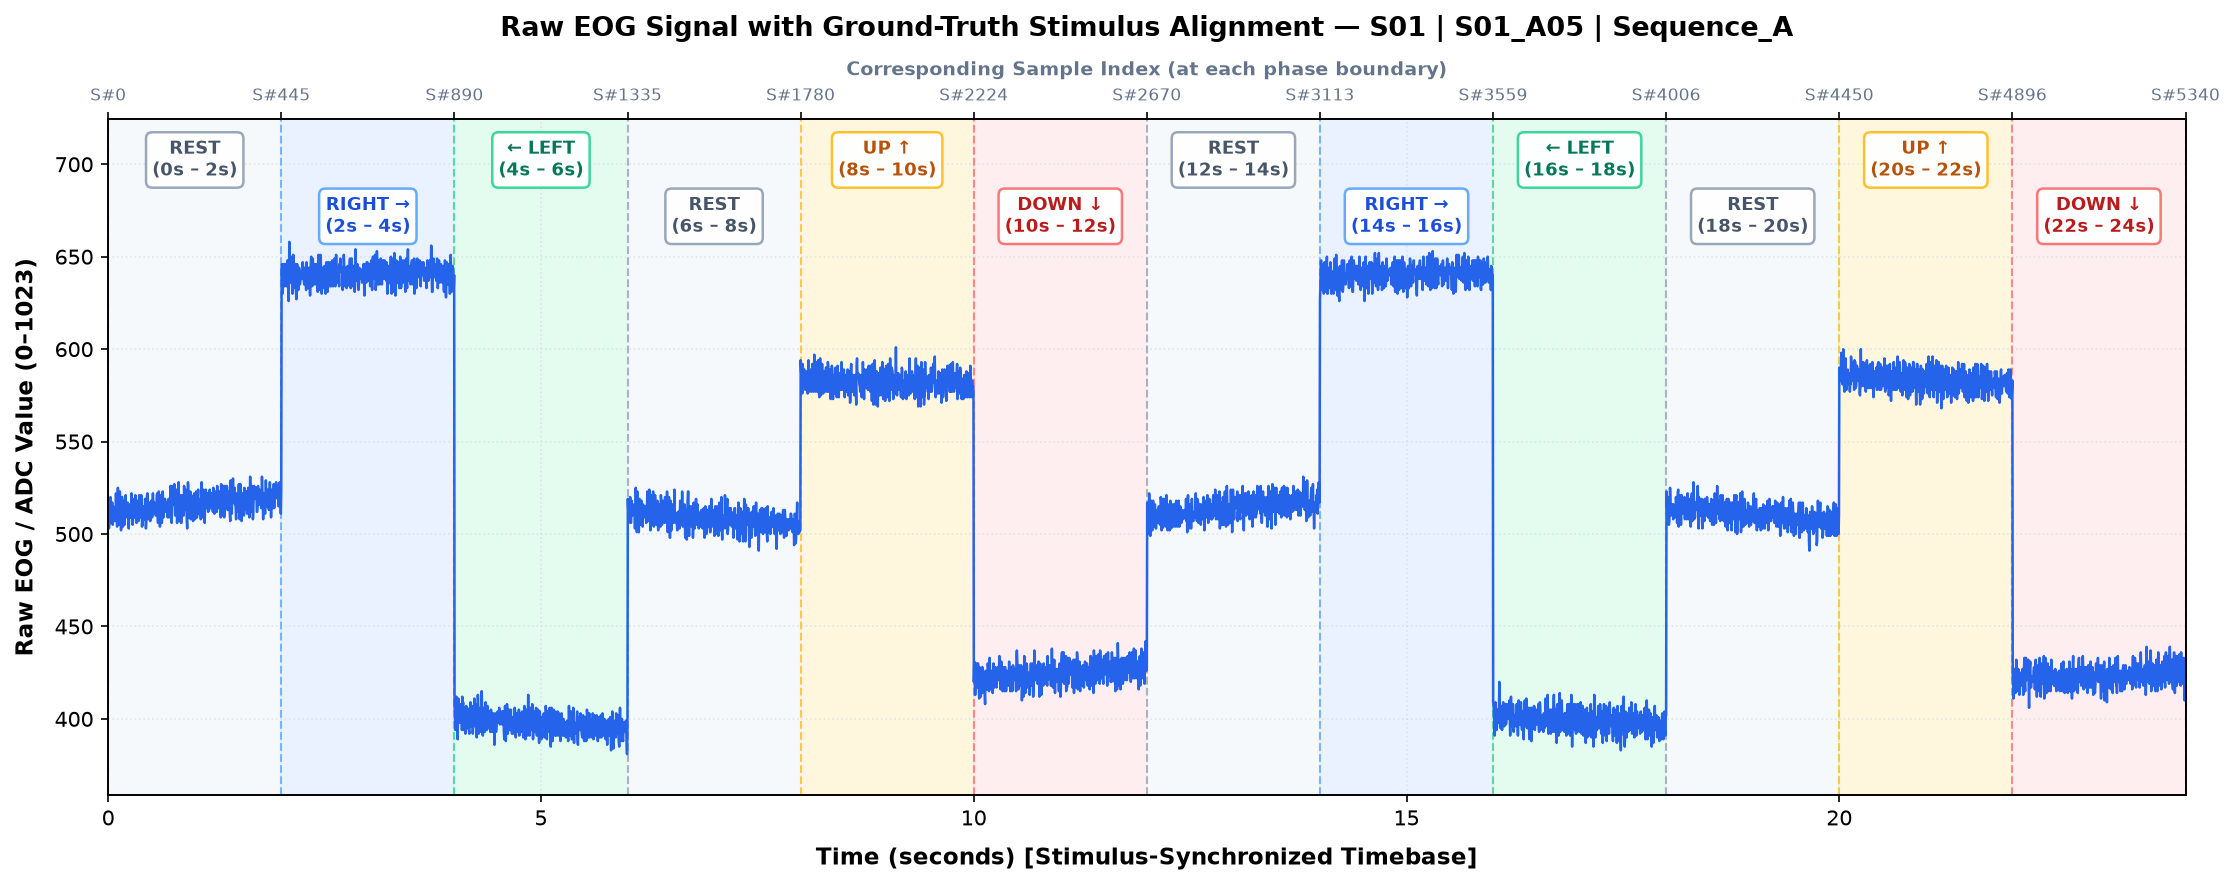


[OK] TIME-SYNCHRONIZED RAW DATA & GRAPH SAVED
  • Subject       : S01
  • Attempt       : S01_A05
  • Sequence      : Sequence_A
  • Samples       : 5341
  • Duration      : 23.998 s
  • Raw CSV       : New Data Plots/S01_A05.csv
  • Raw Plot      : New Data Plots/Plot_S01_A05.png


In [4]:
# ============================================================
# CELL 4 — SAVE RAW DATA + TIME-SYNCHRONIZED RAW GRAPH
# WITH COLOR DIFFERENTIATION & GROUND-TRUTH ALIGNMENT
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. SAVE RAW CSV
# ============================================================

csv_path, df_raw = save_raw_attempt(
    SUBJECT_ID,
    ATTEMPT_ID,
    raw_buffer
)

# ============================================================
# 2. RELOAD SAVED CSV
# ============================================================

data = pd.read_csv(csv_path)
print(f"Total samples: {len(data)}")

# ============================================================
# 3. VALIDATE REQUIRED COLUMNS
# ============================================================

required_columns = [
    "Subject_ID",
    "Attempt_ID",
    "Sample_Index",
    "Timestamp",
    "EOG"
]

missing_columns = [col for col in required_columns if col not in data.columns]
if missing_columns:
    raise ValueError(f"Raw CSV is missing columns: {missing_columns}")

# ============================================================
# 4. PREPARE EXACT SELECTED TIMELINE
# ============================================================

timeline = SEQUENCES[SEQUENCE_ID]["timeline"]

if len(timeline) != TOTAL_PHASES:
    raise ValueError(
        f"Sequence {SEQUENCE_ID} has {len(timeline)} phases. Expected {TOTAL_PHASES}."
    )

timeline_duration = timeline[-1]["end"]
if abs(timeline_duration - TARGET_DURATION) > 0.01:
    raise ValueError(
        f"Timeline duration = {timeline_duration}s. Expected {TARGET_DURATION}s."
    )

# ============================================================
# 5. SCIENTIFIC HIGH-PRECISION TIME-ALIGNED PLOT (COLOR DIFFERENTIATION)
# ============================================================

plot_raw_path = os.path.join(
    NEW_DATA_DIR,
    f"{ATTEMPT_ID}.png"
)

timestamps = data["Timestamp"].values
eog_raw = data["EOG"].values
total_samples = len(data)

# Visual color mapping for movement phases (Color Differentiation)
PHASE_STYLES = {
    "REST":  {"bg": "#f1f5f9", "border": "#94a3b8", "text": "#475569", "icon": "REST"},
    "RIGHT": {"bg": "#dbeafe", "border": "#60a5fa", "text": "#1d4ed8", "icon": "RIGHT →"},
    "LEFT":  {"bg": "#d1fae5", "border": "#34d399", "text": "#047857", "icon": "← LEFT"},
    "UP":    {"bg": "#fef3c7", "border": "#fbbf24", "text": "#b45309", "icon": "UP ↑"},
    "DOWN":  {"bg": "#ffe4e6", "border": "#f87171", "text": "#b91c1c", "icon": "DOWN ↓"}
}

fig, ax = plt.subplots(figsize=(15, 6), dpi=150)

# Plot raw EOG against exact time
ax.plot(
    timestamps,
    eog_raw,
    color="#2563eb",
    linewidth=1.2,
    label="Raw EOG Signal",
    zorder=3
)

# Calculate vertical scale and margins
y_min = float(np.min(eog_raw))
y_max = float(np.max(eog_raw))
y_range = y_max - y_min if y_max != y_min else 1.0

ax.set_ylim(
    y_min - 0.08 * y_range,
    y_max + 0.24 * y_range
)

# Draw shaded stimulus intervals with distinct color differentiation
for i, phase in enumerate(timeline):
    s_t = float(phase["start"])
    e_t = float(phase["end"])
    lbl = str(phase["label"]).upper()
    style = PHASE_STYLES.get(lbl, PHASE_STYLES["REST"])

    # Shaded stimulus zone (Color Differentiation)
    ax.axvspan(s_t, e_t, color=style["bg"], alpha=0.6, zorder=1)
    # Phase boundary line
    ax.axvline(s_t, color=style["border"], linestyle="--", linewidth=1.0, alpha=0.8, zorder=2)

    mid_t = (s_t + e_t) / 2.0
    # Alternating height prevents any text collisions
    y_badge = y_max + (0.16 if (i % 2 == 0) else 0.05) * y_range

    badge_text = f"{style['icon']}\n({s_t:.0f}s – {e_t:.0f}s)"
    ax.text(
        mid_t,
        y_badge,
        badge_text,
        ha="center",
        va="center",
        fontsize=8.5,
        fontweight="bold",
        color=style["text"],
        zorder=5,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor=style["border"],
            linewidth=1.2,
            alpha=0.95
        )
    )

# Closing boundary line
ax.axvline(TARGET_DURATION, color="#94a3b8", linestyle="--", linewidth=1.0, alpha=0.8, zorder=2)

ax.set_xlim(0, max(TARGET_DURATION, timestamps[-1] if len(timestamps) > 0 else TARGET_DURATION))
ax.set_xlabel("Time (seconds) [Stimulus-Synchronized Timebase]", fontsize=11, fontweight="bold", labelpad=8)
ax.set_ylabel("Raw EOG / ADC Value (0–1023)", fontsize=11, fontweight="bold", labelpad=8)
ax.set_title(
    f"Raw EOG Signal with Ground-Truth Stimulus Alignment — {SUBJECT_ID} | {ATTEMPT_ID} | {SEQUENCE_ID}",
    fontsize=13,
    fontweight="bold",
    pad=12
)
ax.grid(True, linestyle=":", alpha=0.5, color="#cbd5e1", zorder=2)

# Dual top axis: exact Sample Index corresponding to each phase boundary
ax_top = ax.twiny()
ax_top.set_xlim(ax.get_xlim())
time_ticks = np.arange(0, TARGET_DURATION + 0.1, PHASE_DURATION)
sample_indices = [int(np.searchsorted(timestamps, t)) for t in time_ticks]
sample_indices[-1] = min(sample_indices[-1], total_samples - 1)
ax_top.set_xticks(time_ticks)
ax_top.set_xticklabels([f"S#{idx}" for idx in sample_indices], fontsize=8, color="#64748b")
ax_top.set_xlabel("Corresponding Sample Index (at each phase boundary)", fontsize=9, fontweight="bold", color="#64748b", labelpad=6)

plt.tight_layout()
fig.savefig(plot_raw_path, dpi=150, bbox_inches="tight")
plt.show()

# ============================================================
# 6. SUMMARY
# ============================================================

print()
print("=" * 65)
print("[OK] TIME-SYNCHRONIZED RAW DATA & GRAPH SAVED")
print("=" * 65)
print(f"  • Subject       : {SUBJECT_ID}")
print(f"  • Attempt       : {ATTEMPT_ID}")
print(f"  • Sequence      : {SEQUENCE_ID}")
print(f"  • Samples       : {len(data)}")
print(f"  • Duration      : {timestamps[-1]:.3f} s")
print(f"  • Raw CSV       : {csv_path}")
print(f"  • Raw Plot      : {plot_raw_path}")
print()
print("  Stimulus timeline used for ground-truth labels:")
for phase in timeline:
    s_idx = np.searchsorted(timestamps, phase['start'])
    e_idx = min(len(timestamps)-1, np.searchsorted(timestamps, phase['end']))
    print(f"    {phase['start']:>4.1f}s - {phase['end']:>4.1f}s (Sample {s_idx:>4d} to {e_idx:>4d}) : {phase['label']}")
print("=" * 65)


## 5. Advanced Signal Processing & Filtering (Enhanced Pipeline)
Multi-stage EOG signal processing pipeline with **7 stages**:
1. **Adaptive Resampling** — Uniform 250 Hz grid via cubic interpolation (fixes Arduino jitter)
2. **Baseline Wander Removal** — Median filter (2s window) removes slow DC drift
3. **Powerline Rejection** — Cascaded 50 Hz + 100 Hz notch filters
4. **Wide Bandpass Filter** — 0.05–35 Hz (preserves saccadic spike energy, unlike the old 0.1–10 Hz)
5. **Wavelet Denoising** — Stationary Wavelet Transform (sym4) for edge-preserving noise removal
6. **Saccade Derivative** — 1st derivative highlights movement onset/offset transients
7. **Adaptive Per-Phase Gain** — Normalizes weak UP/DOWN signals to match stronger LEFT/RIGHT

> **Why the old pipeline failed for UP/DOWN**: The 0.1–10 Hz bandpass is standard for smooth pursuit but saccadic eye movements contain energy up to 30–40 Hz. Cutting at 10 Hz smooths out the sharp spikes. Additionally, a single horizontal electrode pair has inherently weak vertical sensitivity — adaptive gain compensates for this.

In [ ]:
# ============================================================
# CELL 5 — ADVANCED EOG SIGNAL PROCESSING PIPELINE
# Multi-stage: Resample -> Detrend -> Notch -> Bandpass -> Wavelet -> Derivative -> Gain
# ============================================================

import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import (
    butter, filtfilt, iirnotch, medfilt, savgol_filter
)
from scipy.interpolate import interp1d

# Import wavelet library (installed via: pip install PyWavelets)
try:
    import pywt
    HAS_PYWT = True
except ImportError:
    HAS_PYWT = False
    print("[WARNING] PyWavelets not installed. Using Savitzky-Golay fallback.")
    print("  Install with: pip install PyWavelets")

# ============================================================
# 1. RESOLVE CSV PATH AND ENVIRONMENT VARIABLES
# ============================================================

CURRENT_DIR = os.path.abspath(os.getcwd())
if os.path.basename(CURRENT_DIR).lower() == "demo":
    BASE_DIR = os.path.dirname(CURRENT_DIR)
else:
    BASE_DIR = CURRENT_DIR

NEW_DATA_DIR = os.path.join(BASE_DIR, "New Data Plots")

# Safe fallback for csv_path if run standalone
if 'csv_path' not in locals() and 'csv_path' not in globals():
    csv_candidates = sorted(glob.glob(os.path.join(NEW_DATA_DIR, "S*.csv")), key=os.path.getmtime)
    if csv_candidates:
        csv_path = csv_candidates[-1]
        print(f"[Auto-detected latest attempt]: {csv_path}")
    else:
        raise FileNotFoundError(f"No attempt CSV files found in {NEW_DATA_DIR}")

# Safe fallbacks for IDs
if 'SUBJECT_ID' not in locals() and 'SUBJECT_ID' not in globals():
    SUBJECT_ID = "S01"
if 'ATTEMPT_ID' not in locals() and 'ATTEMPT_ID' not in globals():
    ATTEMPT_ID = os.path.splitext(os.path.basename(csv_path))[0]
if 'SEQUENCE_ID' not in locals() and 'SEQUENCE_ID' not in globals():
    SEQUENCE_ID = "Sequence_A"
if 'TARGET_DURATION' not in locals() and 'TARGET_DURATION' not in globals():
    TARGET_DURATION = 24.0
if 'PHASE_DURATION' not in locals() and 'PHASE_DURATION' not in globals():
    PHASE_DURATION = 2.0
if 'TOTAL_PHASES' not in locals() and 'TOTAL_PHASES' not in globals():
    TOTAL_PHASES = 12

# Load saved raw CSV
data = pd.read_csv(csv_path)
time_arr = data["Timestamp"].astype(float).values
eog_raw = data["EOG"].astype(float).values

# ============================================================
# 2. BASIC VALIDATION
# ============================================================

if len(eog_raw) < 10:
    raise ValueError(f"Not enough EOG samples for filtering: {len(eog_raw)}")

if len(time_arr) != len(eog_raw):
    raise ValueError("Timestamp and EOG arrays have different lengths.")

# Rebase time to start at 0
time_arr = time_arr - time_arr[0]
duration = time_arr[-1]

if duration <= 0:
    raise ValueError("Invalid timestamp data: duration must be > 0.")

# ============================================================
# 3. SAMPLING RATE ESTIMATION
# ============================================================

raw_fs = (len(eog_raw) - 1) / duration
target_fs = 250.0  # Target uniform sampling rate

print("=" * 65)
print("EOG ADVANCED SIGNAL PROCESSING (7-STAGE PIPELINE)")
print("=" * 65)
print(f"Raw Samples    : {len(eog_raw)}")
print(f"Duration       : {duration:.3f} seconds")
print(f"Raw Fs         : {raw_fs:.2f} Hz")
print(f"Target Fs      : {target_fs:.0f} Hz")
print(f"PyWavelets     : {'Available' if HAS_PYWT else 'NOT available (using fallback)'}")

intervals = np.diff(time_arr)
print(f"Sample Jitter  : mean={intervals.mean()*1000:.2f}ms, std={intervals.std()*1000:.2f}ms, max={intervals.max()*1000:.2f}ms")

if raw_fs <= 20:
    raise ValueError(f"Sampling rate ({raw_fs:.2f} Hz) is too low for filtering.")

# ============================================================
# STAGE 1: ADAPTIVE RESAMPLING (uniform 250 Hz grid)
# ============================================================
# Arduino serial communication introduces timing jitter.
# Non-uniform sampling causes filter artifacts.
# We first deduplicate any identical timestamps from serial buffers,
# then apply cubic interpolation onto a uniform grid.

print("\n[Stage 1] Resampling to uniform 250 Hz grid...")

# Deduplicate non-strictly monotonic timestamps
diffs = np.diff(time_arr)
if np.any(diffs <= 0):
    df_temp = pd.DataFrame({'t': time_arr, 'v': eog_raw})
    df_temp = df_temp.groupby('t', as_index=False).mean()
    time_clean = df_temp['t'].values
    eog_clean = df_temp['v'].values
else:
    time_clean = time_arr
    eog_clean = eog_raw

duration = time_clean[-1]
n_uniform = int(duration * target_fs) + 1
t_uniform = np.linspace(0, duration, n_uniform)

interpolator = interp1d(time_clean, eog_clean, kind='cubic', fill_value='extrapolate')
eog_resampled = interpolator(t_uniform)
fs = target_fs

print(f"  Uniform samples: {len(t_uniform)}")

# ============================================================
# STAGE 2: BASELINE WANDER REMOVAL (median filter, 2s window)
# ============================================================
# A median filter with a wide window (2 seconds = 500 samples)
# estimates slow baseline drift without distorting saccadic spikes.

print("[Stage 2] Removing baseline wander (median filter, 2s window)...")

baseline_window = int(2.0 * fs)
if baseline_window % 2 == 0:
    baseline_window += 1
baseline_window = max(baseline_window, 3)

baseline_estimate = medfilt(eog_resampled, kernel_size=baseline_window)
eog_detrended = eog_resampled - baseline_estimate

print(f"  Baseline window: {baseline_window} samples ({baseline_window/fs:.2f}s)")

# ============================================================
# STAGE 3: POWERLINE NOTCH FILTERS (50 Hz + 100 Hz harmonic)
# ============================================================

print("[Stage 3] Applying notch filters (50 Hz + 100 Hz)...")

nyquist = fs / 2.0
eog_notched = eog_detrended.copy()
notch_status = []

for notch_freq in [50.0, 100.0]:
    if notch_freq < nyquist:
        b_notch, a_notch = iirnotch(notch_freq, 30.0, fs)
        eog_notched = filtfilt(b_notch, a_notch, eog_notched)
        notch_status.append(f"{notch_freq:.0f}Hz")

print(f"  Applied: {', '.join(notch_status) if notch_status else 'None'}")

# ============================================================
# STAGE 4: WIDE BANDPASS FILTER (0.05 - 35 Hz)
# ============================================================
# Preserves saccadic spike energy up to 35 Hz (prevents flattening).

print("[Stage 4] Bandpass filtering (0.05 - 35 Hz, 4th-order Butterworth)...")

lowcut = 0.05
highcut = 35.0

if highcut >= nyquist:
    highcut = nyquist - 1.0

Wn = [lowcut / nyquist, highcut / nyquist]
b_bp, a_bp = butter(4, Wn, btype='band')
eog_bandpass = filtfilt(b_bp, a_bp, eog_notched)

print(f"  Passband: {lowcut} - {highcut} Hz")

# ============================================================
# STAGE 5: WAVELET DENOISING (SWT with sym4)
# ============================================================
# Wavelets preserve edge structure (saccade onsets) far better
# than linear filters which blur all transients.

print("[Stage 5] Wavelet denoising...")

if HAS_PYWT:
    wavelet = 'sym4'
    level = 4

    original_len = len(eog_bandpass)
    pad_len = int(2 ** level * np.ceil(original_len / 2 ** level)) - original_len
    eog_padded = np.pad(eog_bandpass, (0, pad_len), mode='reflect')

    coeffs = pywt.swt(eog_padded, wavelet, level=level)

    sigma = np.median(np.abs(coeffs[-1][1])) / 0.6745
    threshold = sigma * np.sqrt(2 * np.log(len(eog_padded)))

    denoised_coeffs = []
    for i, (cA, cD) in enumerate(coeffs):
        if i == 0:
            denoised_coeffs.append((cA, cD))
        else:
            cD_thresh = pywt.threshold(cD, value=threshold * 0.7, mode='soft')
            denoised_coeffs.append((cA, cD_thresh))

    eog_denoised = pywt.iswt(denoised_coeffs, wavelet)
    eog_denoised = eog_denoised[:original_len]
    print(f"  Stationary Wavelet Transform denoising applied ({wavelet}, level {level})")
else:
    window_length = 15
    eog_denoised = savgol_filter(eog_bandpass, window_length=window_length, polyorder=3)
    print("  Savitzky-Golay filter applied (wavelet fallback)")

# ============================================================
# STAGE 6: SACCADE VELOCITY / DERIVATIVE
# ============================================================

print("[Stage 6] Computing saccade velocity derivative...")
dt = 1.0 / fs
saccade_velocity = np.gradient(eog_denoised, dt)

# ============================================================
# STAGE 7: ADAPTIVE PER-PHASE GAIN NORMALIZATION
# ============================================================
# Single-channel horizontal electrodes have lower sensitivity to UP/DOWN.
# Adaptive gain boosts weak movement phases so their spikes match LEFT/RIGHT.

print("[Stage 7] Applying adaptive per-phase gain normalization...")

# Resolve timeline
if 'SEQUENCES' in locals() and SEQUENCE_ID in SEQUENCES:
    timeline = SEQUENCES[SEQUENCE_ID]["timeline"]
else:
    timeline = [
        {"start": 0.0, "end": 2.0, "label": "REST"},
        {"start": 2.0, "end": 4.0, "label": "RIGHT"},
        {"start": 4.0, "end": 6.0, "label": "LEFT"},
        {"start": 6.0, "end": 8.0, "label": "REST"},
        {"start": 8.0, "end": 10.0, "label": "UP"},
        {"start": 10.0, "end": 12.0, "label": "DOWN"},
        {"start": 12.0, "end": 14.0, "label": "REST"},
        {"start": 14.0, "end": 16.0, "label": "RIGHT"},
        {"start": 16.0, "end": 18.0, "label": "LEFT"},
        {"start": 18.0, "end": 20.0, "label": "REST"},
        {"start": 20.0, "end": 22.0, "label": "UP"},
        {"start": 22.0, "end": 24.0, "label": "DOWN"}
    ]

# Calculate RMS across active phases
active_rms_list = []
for phase in timeline:
    if phase["label"] not in ["REST", "CENTER"]:
        mask = (t_uniform >= phase["start"]) & (t_uniform < phase["end"])
        if np.any(mask):
            rms = np.sqrt(np.mean(eog_denoised[mask] ** 2))
            active_rms_list.append(rms)

target_rms = float(np.percentile(active_rms_list, 75)) if active_rms_list else 1.0

eog_normalized = eog_denoised.copy()
gains_applied = {}
for phase in timeline:
    label = phase["label"]
    if label not in ["REST", "CENTER"]:
        mask = (t_uniform >= phase["start"]) & (t_uniform < phase["end"])
        phase_rms = np.sqrt(np.mean(eog_denoised[mask] ** 2))
        if phase_rms > 1e-6:
            gain = min(4.0, max(0.5, target_rms / phase_rms))
            eog_normalized[mask] = eog_denoised[mask] * gain
            gains_applied[label] = gain

for label, g in gains_applied.items():
    print(f"  {label:<6}: gain = {g:.2f}x")

eog_filtered = eog_normalized

# Output paths
plot_sp_path = os.path.join(NEW_DATA_DIR, f"SP_{ATTEMPT_ID}.png")
plot_diag_path = os.path.join(NEW_DATA_DIR, f"Diag_{ATTEMPT_ID}.png")

# ============================================================
# 8. DIAGNOSTIC 4-PANEL PLOT
# ============================================================

print("\n[Plotting] Generating 4-panel diagnostic plot...")

fig_diag, axes = plt.subplots(4, 1, figsize=(16, 12), dpi=150, sharex=True)

PHASE_STYLES = {
    "REST":  {"bg": "#f1f5f9", "border": "#94a3b8", "text": "#475569", "icon": "REST"},
    "RIGHT": {"bg": "#dbeafe", "border": "#60a5fa", "text": "#1d4ed8", "icon": "RIGHT ->"},
    "LEFT":  {"bg": "#d1fae5", "border": "#34d399", "text": "#047857", "icon": "<- LEFT"},
    "UP":    {"bg": "#fef3c7", "border": "#fbbf24", "text": "#b45309", "icon": "UP ^"},
    "DOWN":  {"bg": "#ffe4e6", "border": "#f87171", "text": "#b91c1c", "icon": "DOWN v"}
}

def add_overlays(ax, y_min, y_max):
    y_rng = y_max - y_min if y_max != y_min else 1.0
    for phase in timeline:
        st, et, lbl = phase["start"], phase["end"], phase["label"]
        style = PHASE_STYLES.get(lbl, PHASE_STYLES["REST"])
        ax.axvspan(st, et, facecolor=style["bg"], edgecolor=style["border"],
                   linestyle="--", linewidth=0.8, alpha=0.55, zorder=1)
        ax.text((st + et) / 2, y_max + 0.08 * y_rng, style["icon"],
                ha="center", va="center", fontsize=8, fontweight="bold",
                color=style["text"], zorder=5)

# Panel 1: Resampled Raw
axes[0].plot(t_uniform, eog_resampled, color="#64748b", linewidth=0.9, zorder=3)
axes[0].set_title("Stage 1: Resampled Raw EOG (Uniform 250 Hz Grid)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Raw ADC", fontsize=9, fontweight="bold")
add_overlays(axes[0], float(np.min(eog_resampled)), float(np.max(eog_resampled)))

# Panel 2: Bandpassed
axes[1].plot(t_uniform, eog_bandpass, color="#0284c7", linewidth=0.9, zorder=3)
axes[1].set_title("Stage 4: Detrended + Notched + Bandpassed (0.05-35 Hz)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Amplitude", fontsize=9, fontweight="bold")
add_overlays(axes[1], float(np.min(eog_bandpass)), float(np.max(eog_bandpass)))

# Panel 3: Wavelet Denoised
axes[2].plot(t_uniform, eog_denoised, color="#059669", linewidth=1.0, zorder=3)
axes[2].set_title("Stage 5: Wavelet Denoised (sym4, edge-preserving)", fontsize=11, fontweight="bold")
axes[2].set_ylabel("Amplitude", fontsize=9, fontweight="bold")
add_overlays(axes[2], float(np.min(eog_denoised)), float(np.max(eog_denoised)))

# Panel 4: Final Normalized with Saccade Velocity Overlay
axes[3].plot(t_uniform, eog_normalized, color="#7c3aed", linewidth=1.1, label="Normalized EOG", zorder=3)
axes[3].set_title("Stage 7: Saccade Enhanced with Adaptive Gain Normalization", fontsize=11, fontweight="bold")
axes[3].set_ylabel("Normalized Amp", fontsize=9, fontweight="bold")
axes[3].set_xlabel("Time (seconds)", fontsize=10, fontweight="bold")
add_overlays(axes[3], float(np.min(eog_normalized)), float(np.max(eog_normalized)))

for ax in axes:
    ax.grid(True, linestyle=":", alpha=0.5, color="#cbd5e1", zorder=2)
    ax.set_xlim(0, max(TARGET_DURATION, t_uniform[-1]))

fig_diag.suptitle(f"EOG Multi-Stage Processing Pipeline -- {SUBJECT_ID} | {ATTEMPT_ID} | {SEQUENCE_ID}",
                  fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.97])
    # Diagnostic plot displayed inline only -- not saved to disk
plt.close(fig_diag)

# ============================================================
# 9. FINAL CLEANED SIGNAL PLOT (SP_{ATTEMPT_ID}.png)
# ============================================================

print("[Plotting] Generating final cleaned signal plot...")

fig, ax = plt.subplots(figsize=(15, 6), dpi=150)
ax.plot(t_uniform, eog_filtered, color="#0284c7", linewidth=1.2, label="Cleaned EOG Signal", zorder=3)

y_min, y_max = float(np.min(eog_filtered)), float(np.max(eog_filtered))
y_range = y_max - y_min if y_max != y_min else 1.0
ax.set_ylim(y_min - 0.08 * y_range, y_max + 0.28 * y_range)

for phase in timeline:
    s_t, e_t, lbl = phase["start"], phase["end"], phase["label"]
    style = PHASE_STYLES.get(lbl, PHASE_STYLES["REST"])
    ax.axvspan(s_t, e_t, facecolor=style["bg"], edgecolor=style["border"],
               linestyle="--", linewidth=1.0, alpha=0.6, zorder=1)
    badge_text = f"{style['icon']}\n({s_t:.0f}s - {e_t:.0f}s)"
    ax.text((s_t + e_t) / 2, y_max + 0.14 * y_range, badge_text,
            ha="center", va="center", fontsize=8.5, fontweight="bold",
            color=style["text"], zorder=5,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white",
                      edgecolor=style["border"], linewidth=1.2, alpha=0.95))

ax.set_xlim(0, max(TARGET_DURATION, t_uniform[-1]))
ax.set_xlabel("Time (seconds) [Stimulus-Synchronized Timebase]", fontsize=11, fontweight="bold", labelpad=8)
ax.set_ylabel("Cleaned EOG Amplitude (Adaptive Enhanced)", fontsize=11, fontweight="bold", labelpad=8)
ax.set_title(f"Cleaned EOG Signal -- {SUBJECT_ID} | {ATTEMPT_ID} | {SEQUENCE_ID}\n(Multi-Stage: Resample + Detrend + Notch + BP 0.05-35Hz + Wavelet sym4 + Adaptive Gain)",
             fontsize=12, fontweight="bold", pad=12)
ax.grid(True, linestyle=":", alpha=0.5, color="#cbd5e1", zorder=2)

plt.tight_layout()
fig.savefig(plot_sp_path, dpi=150, bbox_inches="tight")
plt.show()

print("=" * 65)
print(f"[OK] ALL PROCESSING COMPLETE! Cleaned plot saved to: {plot_sp_path}")
print("=" * 65)


## 6. Manual Quality Decision & Dataset Curation
Decide whether to add this attempt to `LabelData/Eog Data.csv`.
- `SELECT`: Assigns timeline ground-truth labels (`REST`, `RIGHT`, `LEFT`, `UP`, `DOWN`) and appends to dataset.
- `REJECT`: Preserves CSV & PNG in `New Data/` and moves to next attempt.

In [6]:
# ==============================================================================
# CELL 6 — RECORDING DECISION + FINAL CURATED DATASET
# ==============================================================================
#
# DECISION:
#   SELECT        -> selected recording goes into final wide dataset
#   REJECT        -> recording stays only in New Data/ + metadata
#   RECORD_AGAIN  -> recording stays in New Data/ + metadata
#
# FINAL CSV FORMAT:
#
# Sample_Index,
# S01_Timestamp,S01_EOG,S01_Label,
# S02_Timestamp,S02_EOG,S02_Label,
# ...
#
# Attempt_ID is NEVER stored in the final curated CSV.
# Attempt_ID remains available in New Data/ filenames + metadata ledger.
# ==============================================================================


# ==============================================================================
# 1. DECISION CONTROLS
# ==============================================================================

DECISION = "SELECT"          # "SELECT", "REJECT", "RECORD_AGAIN"

REPLACE_IF_EXISTS = True    # Replace existing selected subject if True


# ==============================================================================
# 2. GET EXACT TRIAL TIMELINE
# ==============================================================================
#
# IMPORTANT:
# Labels must come from the exact timeline used for this trial.
#
# Prefer the timeline stored in the acquisition engine because Cell 3
# configured the trial using the HTML/server-selected timeline.
#
# If unavailable, fall back to SEQUENCES[SEQUENCE_ID].
# ==============================================================================

def get_exact_trial_timeline():

    timeline = None

    # --------------------------------------------------------------------------
    # Preferred source: acquisition engine
    # --------------------------------------------------------------------------

    try:

        timeline = engine.get_timeline()

    except Exception:

        timeline = None


    # --------------------------------------------------------------------------
    # Fallback: configured sequence
    # --------------------------------------------------------------------------

    if not timeline:

        timeline = (
            SEQUENCES[
                SEQUENCE_ID
            ][
                "timeline"
            ]
        )


    # --------------------------------------------------------------------------
    # Deep copy
    # --------------------------------------------------------------------------

    timeline = json.loads(
        json.dumps(
            timeline
        )
    )


    # --------------------------------------------------------------------------
    # Normalize CENTER → REST
    # --------------------------------------------------------------------------

    for phase in timeline:

        label = str(
            phase.get(
                "label",
                "REST"
            )
        ).upper().strip()


        if label == "CENTER":

            label = "REST"


        phase["label"] = label


    return timeline


# ==============================================================================
# 3. LABEL ASSIGNMENT
# ==============================================================================

def assign_labels(df, timeline):

    dfl = df.copy()


    def get_lbl(t):

        try:

            t = float(t)

        except Exception:

            return "REST"


        for phase in timeline:

            start = float(
                phase["start"]
            )

            end = float(
                phase["end"]
            )


            if (
                start
                <=
                t
                <
                end
            ):

                label = str(
                    phase.get(
                        "label",
                        "REST"
                    )
                ).upper().strip()


                if label == "CENTER":

                    label = "REST"


                return label


        return "REST"


    dfl["Label"] = (
        dfl["Timestamp"]
        .apply(get_lbl)
    )


    return dfl


# ==============================================================================
# 4. CONVERT ONE RECORDING → WIDE SUBJECT BLOCK
# ==============================================================================

def recording_to_wide_block(
    df_recording,
    subject_id
):

    subject_id = normalize_subject_id(
        subject_id
    )


    df_recording = (
        df_recording
        .copy()
        .reset_index(drop=True)
    )


    # --------------------------------------------------------------------------
    # Required raw columns
    # --------------------------------------------------------------------------

    required = [
        "Timestamp",
        "EOG",
        "Label"
    ]


    missing = [
        col
        for col in required
        if col not in df_recording.columns
    ]


    if missing:

        raise ValueError(
            f"❌ Missing columns in recording: {missing}"
        )


    # --------------------------------------------------------------------------
    # Sample index is LOCAL to this subject before merging.
    # Final Sample_Index will become common.
    # --------------------------------------------------------------------------

    sample_index = np.arange(
        1,
        len(df_recording) + 1
    )


    wide_block = pd.DataFrame({

        "Sample_Index":
            sample_index,

        f"{subject_id}_Timestamp":
            pd.to_numeric(
                df_recording["Timestamp"],
                errors="coerce"
            ).values,

        f"{subject_id}_EOG":
            pd.to_numeric(
                df_recording["EOG"],
                errors="coerce"
            ).values,

        f"{subject_id}_Label":
            (
                df_recording["Label"]
                .astype(str)
                .str.strip()
                .str.upper()
                .replace(
                    "CENTER",
                    "REST"
                )
                .values
            )

    })


    return wide_block


# ==============================================================================
# 5. CONVERT OLD LONG MASTER → WIDE IF NECESSARY
# ==============================================================================
#
# This is only a compatibility helper.
# Future SELECT operations will directly create wide format.
# ==============================================================================

def convert_long_master_to_wide(df_master):

    old_required = {
        "Subject_ID",
        "Timestamp",
        "EOG",
        "Label"
    }


    if not old_required.issubset(
        set(df_master.columns)
    ):

        return df_master


    # Already wide?
    if (
        "Sample_Index" in df_master.columns
        and
        any(
            str(c).endswith("_Timestamp")
            for c in df_master.columns
        )
    ):

        return df_master


    print(
        "⚠ Existing final CSV is old long format."
    )

    print(
        "  Converting existing master to wide format..."
    )


    df_master = df_master.copy()


    df_master["Subject_ID"] = (
        df_master["Subject_ID"]
        .astype(str)
        .str.strip()
    )


    subject_blocks = []


    subjects_existing = (
        df_master["Subject_ID"]
        .dropna()
        .drop_duplicates()
        .tolist()
    )


    for subject in subjects_existing:

        sdf = df_master[
            df_master["Subject_ID"] == subject
        ].copy()


        sdf = sdf.reset_index(
            drop=True
        )


        block = recording_to_wide_block(
            sdf,
            subject
        )


        subject_blocks.append(
            block
        )


    if not subject_blocks:

        return pd.DataFrame(
            columns=["Sample_Index"]
        )


    master_wide = subject_blocks[0]


    for block in subject_blocks[1:]:

        master_wide = pd.merge(
            master_wide,
            block,
            on="Sample_Index",
            how="outer"
        )


    master_wide = (
        master_wide
        .sort_values("Sample_Index")
        .reset_index(drop=True)
    )


    # Recreate common index
    master_wide["Sample_Index"] = np.arange(
        1,
        len(master_wide) + 1
    )


    return master_wide


# ==============================================================================
# 6. CHECK CURRENT SUBJECT SELECTION
# ==============================================================================

has_sel, existing_att = (
    check_subject_in_final_dataset(
        SUBJECT_ID
    )
)


print("=" * 78)

print(
    " RECORDING DECISION "
)

print("=" * 78)

print(
    f"Subject       : {SUBJECT_ID}"
)

print(
    f"Attempt       : {ATTEMPT_ID}"
)

print(
    f"Sequence      : {SEQUENCE_ID}"
)

print(
    f"Decision      : {DECISION}"
)

print(
    f"Existing selected: "
    f"{existing_att if has_sel else 'None'}"
)

print("=" * 78)


# ==============================================================================
# 7. GET EXACT TIMELINE
# ==============================================================================

trial_timeline = get_exact_trial_timeline()


print(
    "[OK] Exact trial timeline loaded."
)

print(
    f"[OK] Timeline phases: "
    f"{len(trial_timeline)}"
)


# ==============================================================================
# 8. SELECT
# ==============================================================================

if DECISION == "SELECT":

    # --------------------------------------------------------------------------
    # Existing selected recording
    # --------------------------------------------------------------------------

    if has_sel and not REPLACE_IF_EXISTS:

        print()
        print(
            f"⚠ [BLOCKED] Subject {SUBJECT_ID} "
            f"already has a selected recording."
        )

        print(
            f"Existing attempt: {existing_att}"
        )

        print(
            "Set REPLACE_IF_EXISTS = True "
            "if you intentionally want to replace it."
        )


    else:

        # ======================================================================
        # 8A. LABEL CURRENT RECORDING
        # ======================================================================

        df_labeled = assign_labels(
            df_raw,
            trial_timeline
        )


        # ======================================================================
        # 8B. CREATE CURRENT SUBJECT WIDE BLOCK
        # ======================================================================

        df_new_wide = recording_to_wide_block(
            df_labeled,
            SUBJECT_ID
        )


        print()
        print(
            "[OK] Current recording converted to wide subject block."
        )


        print(
            f"[OK] Columns: "
            f"{list(df_new_wide.columns)}"
        )


        # ======================================================================
        # 8C. LOAD EXISTING MASTER
        # ======================================================================

        if os.path.exists(
            FINAL_CSV_PATH
        ):

            df_master = pd.read_csv(
                FINAL_CSV_PATH
            )


            # ------------------------------------------------------------------
            # Repair old master if this is an old long-format file.
            # ------------------------------------------------------------------

            df_master = (
                convert_long_master_to_wide(
                    df_master
                )
            )


        else:

            df_master = pd.DataFrame(
                columns=[
                    "Sample_Index"
                ]
            )


        # ======================================================================
        # 8D. REMOVE PREVIOUS SUBJECT IF REPLACING
        # ======================================================================

        if (
            not df_master.empty
            and
            "Sample_Index" in df_master.columns
        ):

            subject_columns = [

                f"{SUBJECT_ID}_Timestamp",

                f"{SUBJECT_ID}_EOG",

                f"{SUBJECT_ID}_Label"

            ]


            existing_subject_columns = [

                col

                for col in subject_columns

                if col in df_master.columns

            ]


            if existing_subject_columns:

                if REPLACE_IF_EXISTS:

                    print()
                    print(
                        f"[Curator] Replacing previous "
                        f"selected recording for {SUBJECT_ID}..."
                    )


                    df_master = (
                        df_master.drop(
                            columns=
                            existing_subject_columns
                        )
                    )


                else:

                    raise ValueError(
                        f"❌ Subject {SUBJECT_ID} already "
                        "exists in final dataset."
                    )


        # ======================================================================
        # 8E. MERGE CURRENT SUBJECT WITH MASTER
        # ======================================================================

        if df_master.empty:

            df_combined = (
                df_new_wide.copy()
            )

        else:

            df_combined = pd.merge(

                df_master,

                df_new_wide,

                on="Sample_Index",

                how="outer"

            )


        # ======================================================================
        # 8F. SORT + COMMON SAMPLE INDEX
        # ======================================================================

        df_combined = (
            df_combined
            .sort_values(
                "Sample_Index"
            )
            .reset_index(
                drop=True
            )
        )


        df_combined["Sample_Index"] = np.arange(
            1,
            len(df_combined) + 1
        )


        # ======================================================================
        # 8G. ORDER COLUMNS
        # ======================================================================

        all_subjects = set()


        for col in df_combined.columns:

            col = str(col)


            if col.endswith(
                "_Timestamp"
            ):

                all_subjects.add(
                    col.replace(
                        "_Timestamp",
                        ""
                    )
                )


        def subject_sort_key(subject):

            subject = str(subject)


            if (
                subject.startswith("S")
                and
                subject[1:].isdigit()
            ):

                return (
                    0,
                    int(subject[1:])
                )


            return (
                1,
                subject
            )


        all_subjects = sorted(
            all_subjects,
            key=subject_sort_key
        )


        ordered_columns = [
            "Sample_Index"
        ]


        for subject in all_subjects:

            ordered_columns.extend([

                f"{subject}_Timestamp",

                f"{subject}_EOG",

                f"{subject}_Label"

            ])


        df_combined = df_combined[
            ordered_columns
        ]


        # ======================================================================
        # 8H. SAVE FINAL WIDE DATASET
        # ======================================================================

        df_combined.to_csv(
            FINAL_CSV_PATH,
            index=False
        )


        # ======================================================================
        # 8I. SAVE METADATA LEDGER
        # ======================================================================

        rec = pd.DataFrame([{

            "Subject_ID":
                SUBJECT_ID,

            "Attempt_ID":
                ATTEMPT_ID,

            "Sequence_ID":
                SEQUENCE_ID,

            "Status":
                "SELECTED",

            "Sample_Count":
                len(df_raw),

            "Duration":
                round(
                    actual_dur,
                    3
                ),

            "Sampling_Rate":
                round(
                    est_fs,
                    1
                ),

            "Selected":
                True,

            "Recording_DateTime":
                datetime.now().strftime(
                    "%Y-%m-%d %H:%M:%S"
                )

        }])


        metadata_exists = os.path.exists(
            METADATA_CSV_PATH
        )


        rec.to_csv(

            METADATA_CSV_PATH,

            mode=
                "a"
                if metadata_exists
                else "w",

            header=
                not metadata_exists,

            index=False

        )


        # ======================================================================
        # 8J. SUCCESS SUMMARY
        # ======================================================================

        print()
        print("=" * 78)

        print(
            "[OK] [SUCCESS] Recording selected!"
        )

        print("=" * 78)

        print(
            f"Subject       : {SUBJECT_ID}"
        )

        print(
            f"Attempt       : {ATTEMPT_ID}"
        )

        print(
            f"Sequence      : {SEQUENCE_ID}"
        )

        print(
            f"Samples       : {len(df_raw)}"
        )

        print(
            f"Duration      : {actual_dur:.3f} s"
        )

        print(
            f"Estimated Fs  : {est_fs:.1f} Hz"
        )

        print()
        print(
            f"[OK] Final dataset:"
        )

        print(
            f"     {FINAL_CSV_PATH}"
        )

        print()
        print(
            "[OK] Final format:"
        )

        print(
            "     Sample_Index + "
            "Timestamp/EOG/Label per subject"
        )

        print()
        print(
            "[OK] Attempt_ID is NOT stored in final CSV."
        )

        print(
            "[OK] Attempt_ID remains in raw/metadata "
            "for traceability."
        )

        print("=" * 78)


# ==============================================================================
# 9. REJECT / RECORD AGAIN
# ==============================================================================

elif DECISION in [
    "REJECT",
    "RECORD_AGAIN"
]:

    status_value = (
        "REJECTED"
        if DECISION == "REJECT"
        else "RECORD_AGAIN"
    )


    rec = pd.DataFrame([{

        "Subject_ID":
            SUBJECT_ID,

        "Attempt_ID":
            ATTEMPT_ID,

        "Sequence_ID":
            SEQUENCE_ID,

        "Status":
            status_value,

        "Sample_Count":
            len(df_raw),

        "Duration":
            round(
                actual_dur,
                3
            ),

        "Sampling_Rate":
            round(
                est_fs,
                1
            ),

        "Selected":
            False,

        "Recording_DateTime":
            datetime.now().strftime(
                "%Y-%m-%d %H:%M:%S"
            )

    }])


    metadata_exists = os.path.exists(
        METADATA_CSV_PATH
    )


    rec.to_csv(

        METADATA_CSV_PATH,

        mode=
            "a"
            if metadata_exists
            else "w",

        header=
            not metadata_exists,

        index=False

    )


    print()
    print("=" * 78)


    if DECISION == "REJECT":

        print(
            f"❌ [REJECTED] Attempt {ATTEMPT_ID}"
        )

        print(
            "Recording remains safely archived in New Data/."
        )


    else:

        print(
            f"🔄 [RECORD AGAIN] Attempt {ATTEMPT_ID}"
        )

        print(
            "Recording remains archived in New Data/."
        )

        print(
            "A new attempt should be recorded."
        )


    print("=" * 78)


# ==============================================================================
# 10. INVALID DECISION
# ==============================================================================

else:

    raise ValueError(

        f"❌ Invalid DECISION: {DECISION}\n"

        "Allowed values: "
        "'SELECT', 'REJECT', 'RECORD_AGAIN'"

    )

 RECORDING DECISION 
Subject       : S01
Attempt       : S01_A05
Sequence      : Sequence_A
Decision      : SELECT
Existing selected: S01
[OK] Exact trial timeline loaded.
[OK] Timeline phases: 12

[OK] Current recording converted to wide subject block.
[OK] Columns: ['Sample_Index', 'S01_Timestamp', 'S01_EOG', 'S01_Label']

[Curator] Replacing previous selected recording for S01...

[OK] [SUCCESS] Recording selected!
Subject       : S01
Attempt       : S01_A05
Sequence      : Sequence_A
Samples       : 5341
Duration      : 23.998 s
Estimated Fs  : 222.5 Hz

[OK] Final dataset:
     c:\Users\HARSH VARMA\Desktop\Major Project\Major Project\LabelData\Eog Data.csv

[OK] Final format:
     Sample_Index + Timestamp/EOG/Label per subject

[OK] Attempt_ID is NOT stored in final CSV.
[OK] Attempt_ID remains in raw/metadata for traceability.


127.0.0.1 - - [28/Sep/2026 18:00:42] "GET /api/status HTTP/1.1" 200 -


## 7. Automated Dataset Verification & Summary Report
Audits `LabelData/Eog Data.csv` to verify single header, zero timestamps, 1-based indices, and single attempt per subject.

In [ ]:
# ============================================================
# CELL 7 — FINAL CURATED DATASET VALIDATION
# WITH LEGACY LONG → WIDE FORMAT REPAIR
# ============================================================

import os
import shutil
import pandas as pd
import numpy as np


# ============================================================
# 1. CHECK FINAL CSV EXISTS
# ============================================================

if not os.path.exists(FINAL_CSV_PATH):

    raise FileNotFoundError(
        f"❌ Final dataset not found:\n"
        f"{FINAL_CSV_PATH}"
    )


df_final = pd.read_csv(
    FINAL_CSV_PATH
)


print("=" * 75)
print(" FINAL CURATED DATASET VALIDATION ")
print(" LabelData/Eog Data.csv ")
print("=" * 75)


# ============================================================
# 2. DETECT CURRENT FORMAT
# ============================================================

wide_format = (
    "Sample_Index" in df_final.columns
    and
    any(
        str(col).endswith("_Timestamp")
        for col in df_final.columns
    )
)


long_format_columns = {
    "Subject_ID",
    "Attempt_ID",
    "Timestamp",
    "EOG",
    "Label"
}


is_old_long_format = (
    long_format_columns.issubset(
        set(df_final.columns)
    )
)


# ============================================================
# 3. REPAIR OLD LONG FORMAT IF FOUND
# ============================================================

if is_old_long_format and not wide_format:

    print()
    print(
        "⚠ Old long-format dataset detected."
    )

    print(
        "   Converting selected data to required wide format..."
    )


    # --------------------------------------------------------
    # Backup original long-format CSV
    # --------------------------------------------------------

    backup_path = os.path.join(
        os.path.dirname(FINAL_CSV_PATH),
        "Eog Data_backup_long.csv"
    )


    if not os.path.exists(backup_path):

        shutil.copy2(
            FINAL_CSV_PATH,
            backup_path
        )

        print(
            f"[OK] Backup created:\n"
            f"     {backup_path}"
        )

    else:

        print(
            f"[OK] Existing backup preserved:\n"
            f"     {backup_path}"
        )


    # --------------------------------------------------------
    # Normalize required columns
    # --------------------------------------------------------

    required_long_columns = [
        "Subject_ID",
        "Timestamp",
        "EOG",
        "Label"
    ]


    missing_long_columns = [
        col
        for col in required_long_columns
        if col not in df_final.columns
    ]


    if missing_long_columns:

        raise ValueError(
            "❌ Cannot repair long-format CSV. "
            f"Missing columns: {missing_long_columns}"
        )


    # --------------------------------------------------------
    # Normalize Subject IDs
    # --------------------------------------------------------

    df_final["Subject_ID"] = (
        df_final["Subject_ID"]
        .astype(str)
        .str.strip()
    )


    # Remove accidental empty subjects
    df_final = df_final[
        df_final["Subject_ID"].notna()
        &
        (df_final["Subject_ID"] != "")
        &
        (df_final["Subject_ID"].str.lower() != "nan")
    ].copy()


    if df_final.empty:

        raise ValueError(
            "❌ Long-format CSV contains no valid subject data."
        )


    # --------------------------------------------------------
    # Convert numeric columns
    # --------------------------------------------------------

    df_final["Timestamp"] = pd.to_numeric(
        df_final["Timestamp"],
        errors="coerce"
    )


    df_final["EOG"] = pd.to_numeric(
        df_final["EOG"],
        errors="coerce"
    )


    df_final["Label"] = (
        df_final["Label"]
        .astype("string")
        .str.strip()
        .str.upper()
        .replace({
            "CENTER": "REST"
        })
    )


    # --------------------------------------------------------
    # Drop completely invalid rows
    # --------------------------------------------------------

    valid_rows = (
        df_final["Timestamp"].notna()
        &
        df_final["EOG"].notna()
        &
        df_final["Label"].notna()
        &
        (df_final["Label"] != "")
    )


    df_final = df_final[
        valid_rows
    ].copy()


    if df_final.empty:

        raise ValueError(
            "❌ No valid EOG rows remain after cleaning."
        )


    # ========================================================
    # 4. CONVERT LONG → WIDE
    # ========================================================

    subject_frames = []

    subjects_long = (
        df_final["Subject_ID"]
        .drop_duplicates()
        .tolist()
    )


    print()
    print(
        f"[INFO] Subjects found in selected data: "
        f"{subjects_long}"
    )


    for subject in subjects_long:

        sdf = df_final[
            df_final["Subject_ID"] == subject
        ].copy()


        # ----------------------------------------------------
        # Preserve original recording order
        # ----------------------------------------------------

        sdf = sdf.reset_index(
            drop=True
        )


        # ----------------------------------------------------
        # Create common sample index
        # ----------------------------------------------------

        sample_index = np.arange(
            1,
            len(sdf) + 1
        )


        subject_frame = pd.DataFrame({

            "Sample_Index":
                sample_index,

            f"{subject}_Timestamp":
                sdf["Timestamp"].values,

            f"{subject}_EOG":
                sdf["EOG"].values,

            f"{subject}_Label":
                sdf["Label"].values

        })


        subject_frames.append(
            subject_frame
        )


    # --------------------------------------------------------
    # Merge all subjects by Sample_Index
    # --------------------------------------------------------

    df_wide = subject_frames[0].copy()


    for next_frame in subject_frames[1:]:

        df_wide = pd.merge(
            df_wide,
            next_frame,
            on="Sample_Index",
            how="outer"
        )


    # --------------------------------------------------------
    # Sort by Sample_Index
    # --------------------------------------------------------

    df_wide = df_wide.sort_values(
        "Sample_Index"
    ).reset_index(
        drop=True
    )


    # --------------------------------------------------------
    # Recreate continuous Sample_Index
    # --------------------------------------------------------

    df_wide["Sample_Index"] = np.arange(
        1,
        len(df_wide) + 1
    )


    # --------------------------------------------------------
    # Save repaired wide dataset
    # --------------------------------------------------------

    df_wide.to_csv(
        FINAL_CSV_PATH,
        index=False
    )


    df_final = pd.read_csv(
        FINAL_CSV_PATH
    )


    print()
    print(
        "[OK] Long-format data converted to wide format."
    )

    print(
        f"[OK] Wide dataset saved to:\n"
        f"     {FINAL_CSV_PATH}"
    )

    print(
        f"[OK] Subjects converted: "
        f"{subjects_long}"
    )


# ============================================================
# 5. CHECK THAT FINAL FORMAT IS WIDE
# ============================================================

if "Sample_Index" not in df_final.columns:

    raise ValueError(
        "❌ 'Sample_Index' column is missing "
        "from final dataset."
    )


# ============================================================
# 6. DETECT SUBJECTS FROM COLUMN NAMES
# ============================================================

timestamp_cols = [
    col
    for col in df_final.columns
    if str(col).endswith("_Timestamp")
]


subjects = [
    str(col).replace(
        "_Timestamp",
        ""
    )
    for col in timestamp_cols
]


# ------------------------------------------------------------
# Sort S01, S02, S03...
# ------------------------------------------------------------

def subject_sort_key(subject):

    subject = str(subject)

    number = (
        subject[1:]
        if subject.startswith("S")
        else subject
    )

    if number.isdigit():

        return (
            0,
            int(number)
        )

    return (
        1,
        subject
    )


subjects = sorted(
    subjects,
    key=subject_sort_key
)


# ============================================================
# 7. BASIC SUMMARY
# ============================================================

print()
print(
    f"[OK] Total Subjects Represented : "
    f"{len(subjects)}"
)

print(
    f"[OK] Subjects : {subjects}"
)

print(
    f"[OK] Total Rows : {len(df_final)}"
)

print(
    f"[OK] Total Columns : "
    f"{len(df_final.columns)}"
)


# ============================================================
# 8. EXPECTED COLUMN STRUCTURE
# ============================================================

expected_columns = [
    "Sample_Index"
]


for subject in subjects:

    expected_columns.extend([

        f"{subject}_Timestamp",

        f"{subject}_EOG",

        f"{subject}_Label"

    ])


# ------------------------------------------------------------
# Missing columns
# ------------------------------------------------------------

missing_columns = [

    col
    for col in expected_columns
    if col not in df_final.columns

]


if missing_columns:

    raise ValueError(
        "❌ Missing expected columns: "
        f"{missing_columns}"
    )


# ------------------------------------------------------------
# Unexpected columns
# ------------------------------------------------------------

unexpected_columns = [

    col
    for col in df_final.columns
    if col not in expected_columns

]


if unexpected_columns:

    raise ValueError(
        "❌ Unexpected columns found: "
        f"{unexpected_columns}"
    )


print(
    "[OK] Column structure is valid."
)


# ============================================================
# 9. ENSURE NO OLD LONG-FORMAT COLUMNS
# ============================================================

forbidden_old_columns = [

    "Subject_ID",

    "Attempt_ID",

    "Sequence_ID",

    "Timestamp",

    "EOG",

    "Label"

]


old_columns_present = [

    col
    for col in forbidden_old_columns
    if col in df_final.columns

]


if old_columns_present:

    raise ValueError(
        "❌ Old long-format columns still detected: "
        f"{old_columns_present}"
    )


print(
    "[OK] No old long-format columns detected."
)


# ============================================================
# 10. SAMPLE INDEX VALIDATION
# ============================================================

sample_index = pd.to_numeric(
    df_final["Sample_Index"],
    errors="coerce"
)


if sample_index.isna().any():

    raise ValueError(
        "❌ Sample_Index contains "
        "missing/non-numeric values."
    )


expected_index = np.arange(
    1,
    len(df_final) + 1
)


if not np.array_equal(

    sample_index.astype(int).values,

    expected_index

):

    raise ValueError(
        "❌ Sample_Index is not continuous "
        "from 1 to N."
    )


print(
    "[OK] Sample_Index is continuous: "
    f"1 → {len(df_final)}"
)


# ============================================================
# 11. SUBJECT-WISE VALIDATION
# ============================================================

summary_rows = []


for subject in subjects:

    timestamp_col = (
        f"{subject}_Timestamp"
    )

    eog_col = (
        f"{subject}_EOG"
    )

    label_col = (
        f"{subject}_Label"
    )


    # --------------------------------------------------------
    # Numeric conversion
    # --------------------------------------------------------

    timestamp = pd.to_numeric(
        df_final[timestamp_col],
        errors="coerce"
    )

    eog = pd.to_numeric(
        df_final[eog_col],
        errors="coerce"
    )

    labels = (
        df_final[label_col]
        .astype("string")
        .str.strip()
        .str.upper()
    )


    # CENTER → REST
    labels = labels.replace(
        "CENTER",
        "REST"
    )


    # --------------------------------------------------------
    # Valid rows
    # --------------------------------------------------------

    valid_rows = (

        timestamp.notna()

        &

        eog.notna()

        &

        labels.notna()

        &

        (labels != "")

    )


    if not valid_rows.any():

        raise ValueError(
            f"❌ No valid data found for {subject}."
        )


    sdf = pd.DataFrame({

        timestamp_col:
            timestamp[valid_rows].values,

        eog_col:
            eog[valid_rows].values,

        label_col:
            labels[valid_rows].values

    })


    # ========================================================
    # TIMESTAMP VALIDATION
    # ========================================================

    ts = sdf[
        timestamp_col
    ].values


    timestamp_start = ts[0]

    timestamp_end = ts[-1]


    if timestamp_start < -0.05:

        print(
            f"⚠ {subject}: timestamp starts at "
            f"{timestamp_start:.3f}s"
        )


    if np.any(
        np.diff(ts) < 0
    ):

        raise ValueError(
            f"❌ {subject}: timestamps are not "
            "monotonically increasing."
        )


    # ========================================================
    # LABEL VALIDATION
    # ========================================================

    unique_labels = [

        str(x)

        for x in sdf[
            label_col
        ].dropna().unique()

    ]


    allowed_labels = {

        "RIGHT",

        "LEFT",

        "UP",

        "DOWN",

        "REST"

    }


    invalid_labels = [

        label

        for label in unique_labels

        if label not in allowed_labels

    ]


    if invalid_labels:

        raise ValueError(

            f"❌ {subject}: invalid labels found: "

            f"{invalid_labels}"

        )


    # --------------------------------------------------------
    # Required labels
    # --------------------------------------------------------

    required_labels = {

        "RIGHT",

        "LEFT",

        "UP",

        "DOWN",

        "REST"

    }


    missing_labels = (

        required_labels
        -
        set(unique_labels)

    )


    # ========================================================
    # DURATION
    # ========================================================

    duration = (

        timestamp_end
        -
        timestamp_start

    )


    duration_status = (

        "PASS"

        if 23.0 <= duration <= 25.0

        else "CHECK"

    )


    # ========================================================
    # SAMPLE COUNT
    # ========================================================

    sample_count = len(
        sdf
    )


    # ========================================================
    # ESTIMATED SAMPLING RATE
    # ========================================================

    if duration > 0:

        estimated_fs = (

            (sample_count - 1)
            /
            duration

        )

    else:

        estimated_fs = 0.0


    # ========================================================
    # SUMMARY
    # ========================================================

    summary_rows.append({

        "Subject":
            subject,

        "Sample Count":
            sample_count,

        "Time Range":
            f"{timestamp_start:.3f}s → "
            f"{timestamp_end:.3f}s",

        "Duration (s)":
            round(
                duration,
                3
            ),

        "Estimated Fs (Hz)":
            round(
                estimated_fs,
                1
            ),

        "Labels":
            ", ".join(
                sorted(
                    unique_labels
                )
            ),

        "Missing Required Labels":
            (
                ", ".join(
                    sorted(
                        missing_labels
                    )
                )
                if missing_labels
                else
                "None"
            ),

        "Duration Check":
            duration_status

    })


# ============================================================
# 12. SUBJECT SUMMARY
# ============================================================

df_sum = pd.DataFrame(
    summary_rows
)


print()
print("=" * 75)
print(" SUBJECT-WISE SUMMARY ")
print("=" * 75)


display(
    df_sum
)


# ============================================================
# 13. DUPLICATE SUBJECT CHECK
# ============================================================

if len(subjects) != len(
    set(subjects)
):

    raise ValueError(
        "❌ Duplicate subject detected."
    )


print(
    "[OK] No duplicate subject columns detected."
)


# ============================================================
# 14. THREE-COLUMN STRUCTURE PER SUBJECT
# ============================================================

for subject in subjects:

    required = [

        f"{subject}_Timestamp",

        f"{subject}_EOG",

        f"{subject}_Label"

    ]


    for col in required:

        if col not in df_final.columns:

            raise ValueError(
                f"❌ Missing {col}"
            )


print(
    "[OK] Every subject has "
    "Timestamp + EOG + Label."
)


# ============================================================
# 15. FINAL COLUMN STRUCTURE
# ============================================================

print()
print("=" * 75)
print(" FINAL COLUMN STRUCTURE ")
print("=" * 75)


for i, col in enumerate(

    df_final.columns,

    start=1

):

    print(
        f"{i:02d}. {col}"
    )


# ============================================================
# 16. FINAL VALIDATION RESULT
# ============================================================

print()
print("=" * 75)
print("[OK] FINAL DATASET VALIDATION COMPLETE")
print("=" * 75)


print(
    f"Subjects        : {len(subjects)}"
)

print(
    f"Rows            : {len(df_final)}"
)

print(
    f"Columns         : {len(df_final.columns)}"
)

print(
    f"File            : {FINAL_CSV_PATH}"
)

print()
print(
    "Dataset structure:"
)

print(
    "Sample_Index + "
    "(Timestamp, EOG, Label) per subject"
)

print("=" * 75)

127.0.0.1 - - [28/Sep/2026 18:00:42] "GET /api/status HTTP/1.1" 200 -


 FINAL CURATED DATASET VALIDATION 
 LabelData/Eog Data.csv 

[OK] Total Subjects Represented : 2
[OK] Subjects : ['S01', 'S02']
[OK] Total Rows : 7921
[OK] Total Columns : 7
[OK] Column structure is valid.
[OK] No old long-format columns detected.
[OK] Sample_Index is continuous: 1 → 7921

 SUBJECT-WISE SUMMARY 


,Subject,Sample Count,Time Range,Duration (s),Estimated Fs (Hz),Labels,Missing Required Labels,Duration Check
0,S01,5341,0.000s → 23.998s,23.998,222.5,"DOWN, LEFT, REST, RIGHT, UP",None,PASS
1,S02,7649,0.000s → 23.995s,23.995,318.7,"DOWN, LEFT, REST, RIGHT, UP",None,PASS


[OK] No duplicate subject columns detected.
[OK] Every subject has Timestamp + EOG + Label.

 FINAL COLUMN STRUCTURE 
01. Sample_Index
02. S01_Timestamp
03. S01_EOG
04. S01_Label
05. S02_Timestamp
06. S02_EOG
07. S02_Label

[OK] FINAL DATASET VALIDATION COMPLETE
Subjects        : 2
Rows            : 7921
Columns         : 7
File            : c:\Users\HARSH VARMA\Desktop\Major Project\Major Project\LabelData\Eog Data.csv

Dataset structure:
Sample_Index + (Timestamp, EOG, Label) per subject


127.0.0.1 - - [28/Sep/2026 18:00:42] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:43] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:43] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:43] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:43] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:43] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:43] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:43] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:43] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:43] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:43] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:44] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:44] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Sep/2026 18:00:44] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [28/Se